# LiDAR point cloud time series analysis of morphological changes in beach-dune environment

Teaching Assistent: Daan Hulskemper (d.c.hulskemper@tudelft.nl)

This assignment and examples are based on [*Py4dgeo*](https://github.com/3dgeo-heidelberg/py4dgeo) and [*E-TRAINEE*](https://github.com/3dgeo-heidelberg/etrainee) notebooks.

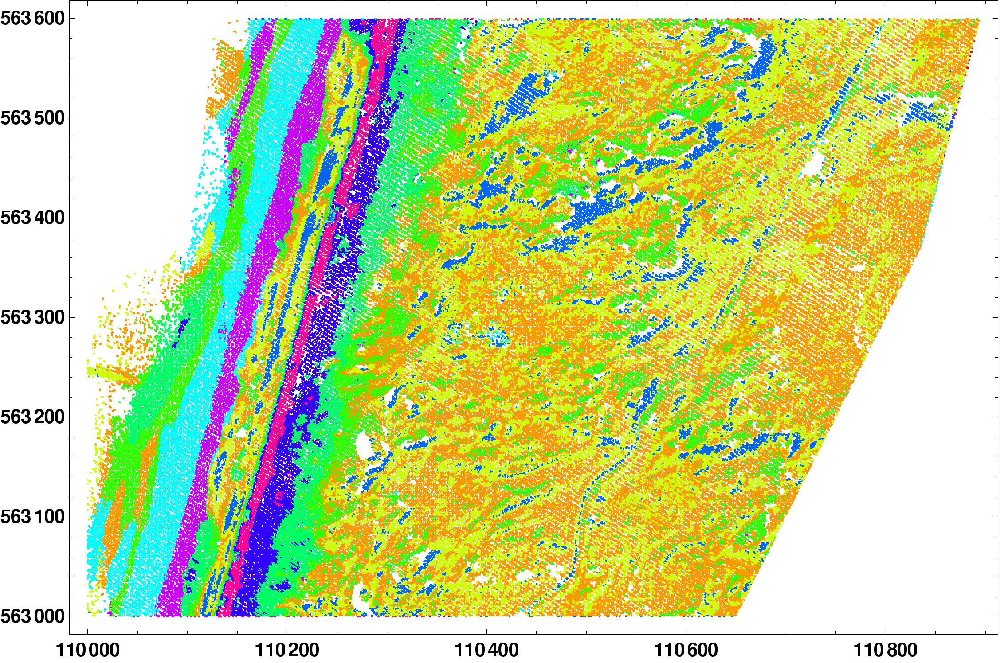

#### Goal
In this assignment you are going to make use of point cloud time series analysis methods as implemented in *py4dgeo* (Anders et al., 2026).
The goal is to assess morphological change as measured by annual aerial LiDAR data.
In other words, you are going to identify areas of the beach and dune that somehow behave similar over time, e.g., gradual deposition in vegetated dunes.
In this notebook several hints on how to setup and use *py4dgeo* for your analysis are provided.

#### Report

Report your answers and code in this notebook and hand-in the notebook itself. Or, alternatively, write your answers in a text-editor of choice and deliver in PDF format, with your code seperately.

#### Data
Please download the annual aerial **JarKus** data of the same tile for (at least) six years at [GeoTiles](https://geotiles.citg.tudelft.nl/). Make sure these years have overlap with the years you used in the first small assignment. For Texel (Prins Hendrik Zanddijk) there is not enough data, so please choose another one this time.

* Hargen (14CZ1)
* Texel (de Hors) (09DN1)
* Ameland (west) (01HN1)
* Springert duinen (64FN2)
* Zandmotor (30DZ1)

#### Preperation (no grading)
1. Clip an appropriate subset of your point clouds either in *CloudCompare* or in Python. Make sure your point clouds are not too big such that you can process the full set within your RAM. For example, only cut out a 2 000 m cross-shore extent from dune to beach. 
2. Follow the steps in the code below to obtain a *py4dgeo* `SpatiotemporalAnalysis` object, and compute the M3C2 (Multi-scale Model-to-Model Cloud Comparison) distances in upward direction for your full point cloud time series with respect to your first cloud. Consider what these distances mean physically.

For the next steps make sure you obtain a time series without NaNs (missing data) either by masking or interpolation.

3. Cluster your elevation change using the distances per epoch (`analysis.distances`) as features (number of features == number of epochs) using KMeans clustering (see f.e. Kuschnerus et al., 2021). Test varying values for K. 
4. As another method to identify characteristic paterns of change, use principal component analysis (PCA; also referred to as empirical orthogonal functions), and compute the loadings and scores per component. Hint: For this technique, the `analysis.distances` should be represented as a two-dimensional array in which the rows correspond to different epochs, and the columns correspond to each individual [x, y] coordinate where a z- or surface change value is represented. 

#### Questions (graded)
1. Visualise your subset for one epoch. What is the extent? What additional properties do your point clouds have other than XYZ coordinates? How many points do the point clouds of the different epochs contain? What are the point densities? 
2. What M3C2 (Multi-scale Model-to-Model Cloud Comparison) parameters did you choose and why? What is the value of using M3C2 over cloud-to-cloud distance computation, or rasterization and consecutive DEM differencing?
3. Visualise your time series of M3C2 distances using a map or 3D plot per epoch. Describe the patterns of change you can visually identify. Discuss what could be potential physical reasons for these change patterns to exist.
4. Based on the patterns of change you visually identified, select (at least) three different corepoints and visualise their elevation change over time. Are they representative for a larger region of your dataset?
5. Visualise in a map or 3D plot the KMeans cluster labels per corepoint and the respective centroid/average time series per cluster for two values of K. Make sure the colours of your map correspond to the colours of the time series. Describe how the grouping changes in space and time for different values of K. What type of change patterns are added when you compute a larger number of clusters? Are they representative of actual physical processes?
6. Choose a number of clusters which you find best captures the variability of the changes occurring in your dataset. Argue why. What would be a data-driven way to select an appropriate cluster number?
7. For this chosen number of clusters: how does the grouping compare to your manually identified patterns of change in Q3? Are the same regions grouped together? If not, what could explain the difference/likeness? How does the spatial grouping relate to the vegetation presence you identified in the last assignment? What could be a physical explanation for this?
8. Visualise the PCA loadings (spatial) and scores (temporal) of the first three components. How much of the variance in the data does each of the components explain? Interpret the PCA loadings and scores. How do they compare to the identified Kmeans clusters? Are they showing similar patterns?
10. What is the meaning of the loading and score of the PCA compared to the label and centroid of the KMeans clusters? Could you combine both methods? How?
11. Which method is most insightful (Manual M3C2 change interpretation, Kmeans or PCA?) for your dataset? Argue why given the dataset size, diversity in the elevation change patterns, and nature of the methods.
  

# Zandmotor Analysis, 2018 - 2023 

**Name:** Emelia Ceballos Notman 
**Student ID:** 6813216


In [29]:
# install necessary libraries (if needed)
!pip install py4dgeo numpy matplotlib scikit-learn pandas "laspy[lazrs]" rasterio

2493.01s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


In [30]:
# import necessary libraries
import numpy as np
import py4dgeo
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from pathlib import Path
import laspy
import rasterio
import pandas as pd

In [49]:
# Cropped every year to the exact footprint of the 2018 RGB clip of assignment 1. This keeps the
# same map coordinates (and therefore the same beach-dune area) in all epochs.
reference_raster = Path("2018_RGB_30DZ1_Clip.tif")
with rasterio.open(reference_raster) as raster:
    if raster.crs is None or raster.crs.to_epsg() != 28992:
        raise ValueError(f"Expected the reference raster in EPSG:28992, got {raster.crs}")
    min_x, min_y, max_x, max_y = raster.bounds

# The input names differ by year, so list them explicitly to ensure the same
# six epochs (2018-2023) are processed and no unrelated LAZ files are included.
source_files = {
    2018: Path("c_Zandmotor2018_30dz1.laz"),
    2019: Path("c_Zandmotor2019_30dz1.laz"),
    2020: Path("C_Zandmotor2020_30DZ1.LAZ"),
    2021: Path("C_Zandmotor2021_30DZ1.LAZ"),
    2022: Path("C_Zandmotor2022_30DZ1.LAZ"),
    2023: Path("C_Zandmotor2023(Kust)_30DZ1.LAZ"),
}
missing_files = [str(path) for path in source_files.values() if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing point-cloud input(s): {missing_files}")

output_dir = Path("clipped_point_clouds")
output_dir.mkdir(parents=True, exist_ok=True)
crop_results = []

def crop_to_reference_bounds(source_path, output_path):
    # Read/write in chunks so the full 10-66 million point clouds do not need
    # to be loaded into memory. Slicing each LAS record retains its attributes.
    with laspy.open(source_path) as source:
        source_count = source.header.point_count
        with laspy.open(output_path, mode="w", header=source.header) as destination:
            for points in source.chunk_iterator(1_000_000):
                inside = (
                    (points.x >= min_x)
                    & (points.x <= max_x)
                    & (points.y >= min_y)
                    & (points.y <= max_y)
                )
                if inside.any():
                    destination.write_points(points[inside])

    # Check the written file, not just the in-memory mask, to catch empty or
    # incorrectly bounded outputs before they are used in the time series.
    with laspy.open(output_path) as clipped:
        clipped_count = clipped.header.point_count
        clipped_mins = clipped.header.mins
        clipped_maxs = clipped.header.maxs
    if clipped_count == 0:
        raise ValueError(f"No points from {source_path} fall inside the reference bounds")
    if (
        clipped_mins[0] < min_x - 0.001
        or clipped_mins[1] < min_y - 0.001
        or clipped_maxs[0] > max_x + 0.001
        or clipped_maxs[1] > max_y + 0.001
    ):
        raise ValueError(f"Clipped output {output_path} extends outside the reference bounds")
    return source_count, clipped_count

for year, source_path in source_files.items():
    output_path = output_dir / f"{year}_Zandmotor_30DZ1_clipped.laz"
    source_count, clipped_count = crop_to_reference_bounds(source_path, output_path)
    crop_results.append(
        {
            "year": year,
            "source_points": source_count,
            "clipped_points": clipped_count,
            "output_file": str(output_path),
        }
    )

print(
    f"Shared EPSG:28992 bounds: x={min_x:.2f} to {max_x:.2f} m; "
    f"y={min_y:.2f} to {max_y:.2f} m "
    f"({max_x - min_x:.2f} m by {max_y - min_y:.2f} m)"
)
pd.DataFrame(crop_results)

Shared EPSG:28992 bounds: x=72353.25 to 73351.00 m; y=451909.50 to 452464.50 m (997.75 m by 555.00 m)


,year,source_points,clipped_points,output_file
0,2018,14664666,1334663,clipped_point_clouds/2018_Zandmotor_30DZ1_clip...
1,2019,12356615,1151116,clipped_point_clouds/2019_Zandmotor_30DZ1_clip...
2,2020,37941471,3369948,clipped_point_clouds/2020_Zandmotor_30DZ1_clip...
3,2021,66040347,6025727,clipped_point_clouds/2021_Zandmotor_30DZ1_clip...
4,2022,62504109,5718088,clipped_point_clouds/2022_Zandmotor_30DZ1_clip...
5,2023,38336867,3277336,clipped_point_clouds/2023_Zandmotor_30DZ1_clip...


We first prepare the analysis by compiling the list of files (epochs) and reading the timestamps from the file names into `datetime` objects. Use your clipped point cloud files and timestamps to create a py4dgeo `SpatiotemporalAnalysis` object.

In [50]:
# Sorted list of point clouds (time series), make sure they go from first to last
# "pc_dir tells python to look for the folder name, pc_dir.glob("*_clipped.laz") finds files in that folder whose names end in _clipped.laz.
# sorted() puts the filenames in order since they start with the year they will be sorted chronologically. The result is a list of file paths to the point clouds.
pc_dir = Path("clipped_point_clouds")
pc_list = sorted(str(path) for path in pc_dir.glob("*_clipped.laz"))

# Filenames start with the year, so the sorted list is chronological.
# py4dgeo timestamps must match that order, including the 2018 reference cloud.
# The "if" check stops with an error unless exactly six files are found. This helps catch missing or extra files before analysis.
# "pd.to_datetime(...)" reads the first four characters of each filename as a year and turns it into a date. Those dates are January 1 by default for each year.
# "print(...)" shows each date alongside its file so you can check the order.  
if len(pc_list) != 6:
    raise ValueError(f"Expected six clipped epochs for 2018-2023, found {len(pc_list)}")
timestamps = [pd.to_datetime(Path(name).name[:4], format="%Y") for name in pc_list]
print(list(zip(timestamps, pc_list)))


[(Timestamp('2018-01-01 00:00:00'), 'clipped_point_clouds/2018_Zandmotor_30DZ1_clipped.laz'), (Timestamp('2019-01-01 00:00:00'), 'clipped_point_clouds/2019_Zandmotor_30DZ1_clipped.laz'), (Timestamp('2020-01-01 00:00:00'), 'clipped_point_clouds/2020_Zandmotor_30DZ1_clipped.laz'), (Timestamp('2021-01-01 00:00:00'), 'clipped_point_clouds/2021_Zandmotor_30DZ1_clipped.laz'), (Timestamp('2022-01-01 00:00:00'), 'clipped_point_clouds/2022_Zandmotor_30DZ1_clipped.laz'), (Timestamp('2023-01-01 00:00:00'), 'clipped_point_clouds/2023_Zandmotor_30DZ1_clipped.laz')]


Now we use the point cloud files and timestamp information to create a `SpatiotemporalAnalysis` object, which is the **main data structure for 3D time series in `py4dgeo`**. The data object is backed by an archive file (zip), which needs to be specified when instantiating the object:

In [51]:
# A zip archive folder is created to store the analysis data.
import os
os.makedirs("data", exist_ok=True)
#This following line creates a py4dgeo.SpatiotemporalAnalysis object and stores it in the variable analysis.
#force=True tells py4dgeo to create a new analysis archive even if one already exists at that path. That can overwrite the existing archive and its contents.

analysis = py4dgeo.SpatiotemporalAnalysis('data.zip', force=True)


[2026-10-15 09:10:57][INFO] Creating analysis file /Users/emelia/Documents/Zandmotor_Multispectral/data.zip



The concept of the py4dgeo `SpatiotemporalAnalysis` object is to add a time series of 3D point clouds in terms of their change values to one global reference epoch. These change values are derived for a set of core points using the M3C2 algorithm. With each epoch added as M3C2 distances compared to the reference epoch, we also add the timestamp to be usable in time series analysis.

As reference epoch, you use the first epoch in our time series (i.e., list of point clouds):

In [52]:
# This code chooses the first point cloud as the baseline for comparing the rest of the time series.
# specify the reference epoch (first epoch). 
# reference_epoch_file = pc_list[0] selects the first item in pc_list.
reference_epoch_file = pc_list[0]

# read the reference epoch and set the timestamp
reference_epoch = py4dgeo.read_from_las(reference_epoch_file)
reference_epoch.timestamp = timestamps[0]

# set the reference epoch in the spatiotemporal analysis object
# analysis.reference_epoch = reference_epoch sets it as the analysis’s reference. Later clouds are compared against this baseline.
analysis.reference_epoch = reference_epoch

[2026-10-15 09:11:01][INFO] Reading point cloud from file '/Users/emelia/Documents/Zandmotor_Multispectral/clipped_point_clouds/2018_Zandmotor_30DZ1_clipped.laz'
[2026-10-15 09:11:01][INFO] Building KDTree structure with leaf parameter 10
[2026-10-15 09:11:02][INFO] Saving epoch to file '/var/folders/8k/j5z3_zps3d32cy8fts1846sh0000gn/T/tmpl5l8fcty/reference_epoch.zip'
[2026-10-15 09:11:02][INFO] Saving a file without normals.


## Question 1: Visualising and properties of the epochs

Per-epoch point-cloud summary:


,Epoch,File,Points,X extent,Y extent,Z extent,XY area (coordinate units^2),Average density (points/coordinate units^2),Points with non-finite XYZ,Additional dimensions,Within-epoch attribute variation / missing values
0,2018,2018_Zandmotor_30DZ1_clipped.laz,1334663,72353.25 to 73351.00,451909.50 to 452464.50,-0.65 to 14.90,553750.695000,2.410224,0,"intensity, return_number, number_of_returns, scan_direction_flag, edge_of_flight_line, classification, synthetic, key_point, withheld, scan_angle_rank, user_data, point_source_id, gps_time",intensity: varies 1 to 65532; non-finite=0; return_number: varies 1 to 5; non-finite=0; number_of_returns: varies 1 to 5; non-finite=0; scan_direction_flag: constant at 0; non-finite=0; edge_of_flight_line: constant at 0; non-finite=0; classification: varies 1 to 9; non-finite=0; synthetic: constant at 0; non-finite=0; key_point: constant at 0; non-finite=0; withheld: constant at 0; non-finite=0; scan_angle_rank: varies -31 to 35; non-finite=0; user_data: constant at 2; non-finite=0; point_source_id: varies 14 to 19; non-finite=0; gps_time: varies 2.05939e+08 to 2.05943e+08; non-finite=0
1,2019,2019_Zandmotor_30DZ1_clipped.laz,1151116,72353.25 to 73351.00,451909.50 to 452464.50,-0.96 to 43.15,553750.695000,2.078762,0,"intensity, return_number, number_of_returns, scan_direction_flag, edge_of_flight_line, classification, synthetic, key_point, withheld, scan_angle_rank, user_data, point_source_id, gps_time",intensity: varies 7 to 10927; non-finite=0; return_number: varies 1 to 5; non-finite=0; number_of_returns: varies 1 to 5; non-finite=0; scan_direction_flag: constant at 0; non-finite=0; edge_of_flight_line: varies 0 to 1; non-finite=0; classification: varies 1 to 9; non-finite=0; synthetic: constant at 0; non-finite=0; key_point: constant at 0; non-finite=0; withheld: constant at 0; non-finite=0; scan_angle_rank: varies -31 to 30; non-finite=0; user_data: constant at 0; non-finite=0; point_source_id: varies 2 to 8; non-finite=0; gps_time: varies 2.56469e+08 to 2.56472e+08; non-finite=0
2,2020,2020_Zandmotor_30DZ1_clipped.laz,3369948,72353.25 to 73351.00,451909.50 to 452464.50,-0.95 to 43.77,553750.695000,6.085677,0,"intensity, return_number, number_of_returns, scan_direction_flag, edge_of_flight_line, classification, synthetic, key_point, withheld, scan_angle_rank, user_data, point_source_id, gps_time, Reflectance, Deviation",intensity: varies 57 to 4769; non-finite=0; return_number: varies 1 to 5; non-finite=0; number_of_returns: varies 1 to 5; non-finite=0; scan_direction_flag: constant at 0; non-finite=0; edge_of_flight_line: varies 0 to 1; non-finite=0; classification: varies 1 to 9; non-finite=0; synthetic: constant at 0; non-finite=0; key_point: constant at 0; non-finite=0; withheld: constant at 0; non-finite=0; scan_angle_rank: varies -30 to 29; non-finite=0; user_data: constant at 6; non-finite=0; point_source_id: varies 1 to 7; non-finite=0; gps_time: varies 2.88171e+08 to 2.88174e+08; non-finite=0; Reflectance: varies -20.67 to 26.13; non-finite=0; Deviation: varies 0 to 65535; non-finite=0
3,2021,2021_Zandmotor_30DZ1_clipped.laz,6025727,72353.25 to 73351.00,451909.50 to 452464.50,-0.92 to 43.81,553751.250000,10.881649,0,"intensity, return_number, number_of_returns, scan_direction_flag, edge_of_flight_line, classification, synthetic, key_point, withheld, scan_angle_rank, user_data, point_source_id, gps_time, Reflectance, Deviation",intensity: varies 58 to 4878; non-finite=0; return_number: varies 1 to 5; non-finite=0; number_of_returns: varies 1 to 5; non-finite=0; scan_direction_flag: varies 0 to 1; non-finite=0; edge_of_flight_line: varies 0 to 1; non-finite=0; classification: varies 1 to 9; non-finite=0; synthetic: constant at 0; non-finite=0; key_point: constant at 0; non-finite=0; withheld: constant at 0; non-finite=0; scan_angle_rank: varies -30 to 30; non-finite=0; user_data: varies 6 to 7; non-finite=0; point_source_id: varies 26 to 32; non-finite=0; gps_time: varies 3.18581e+08

Additional dimensions: availability across epochs:


,Dimension,Present in epochs
0,Deviation,"2020, 2021, 2022, 2023"
1,Reflectance,"2020, 2021, 2022, 2023"
2,classification,"2018, 2019, 2020, 2021, 2022, 2023"
3,edge_of_flight_line,"2018, 2019, 2020, 2021, 2022, 2023"
4,gps_time,"2018, 2019, 2020, 2021, 2022, 2023"
5,intensity,"2018, 2019, 2020, 2021, 2022, 2023"
6,key_point,"2018, 2019, 2020, 2021, 2022, 2023"
7,number_of_returns,"2018, 2019, 2020, 2021, 2022, 2023"
8,overlap,"2022, 2023"
9,point_source_id,"2018, 2019, 2020, 2021, 2022, 2023"


[2026-10-15 20:26:26][INFO] Reading point cloud from file '/Users/emelia/Documents/Zandmotor_Multispectral/clipped_point_clouds/2018_Zandmotor_30DZ1_clipped.laz'


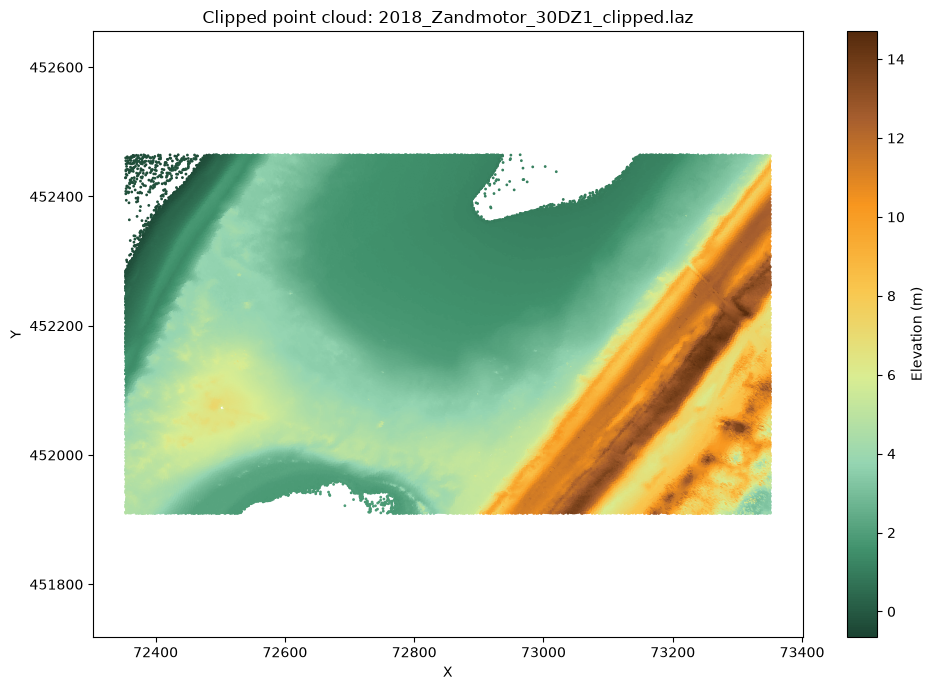

Density is point count divided by XY bounding-box area (an average, not local density); its units depend on the coordinate units. Non-finite attribute counts detect NaN/inf; integer LAS fields may use domain-specific sentinel conventions.


In [188]:
from IPython.display import display

# pc_list contains clipped point-cloud paths in chronological order.
# Also accept (timestamp, path) entries if the list was built that way.
# Build the ordered list of LAS/LAZ files to analyse.
if "pc_list" in globals():
    raw_files = pc_list
else:
    # Fallback: use the notebook's clipped_point_clouds directory if no explicit list exists.
    base = Path.cwd() / "clipped_point_clouds"
    if base.is_dir():
        raw_files = sorted(base.glob("*"))
    else:
        raise NameError(
            "No point-cloud list found. Define `pc_list` before this cell, "
            "or place the clipped LAS/LAZ files in `clipped_point_clouds/`."
        )

files = [
    Path(item[1] if isinstance(item, tuple) else item)
    for item in raw_files
]

# Scan in chunks so attribute checks do not load each full cloud into memory.
rows = []
attribute_sets = []

for path in files:
    if not path.is_file():
        if not path.is_file():
            # The notebook stores filenames only, but the LAS files are often under a data subdirectory.
            candidate = Path.cwd() / "clipped_point_clouds" / path.name
            if candidate.is_file():
                path = candidate
            else:
                raise FileNotFoundError(
                    f"Point-cloud file not found: {path.resolve()}. "
                    f"Checked {Path.cwd()} and {Path.cwd() / 'clipped_point_clouds'}. "
                    "Make sure the files exist in the expected directory."
                )

    with laspy.open(path) as las:
        header = las.header
        point_count = int(header.point_count)
        dimensions = list(header.point_format.dimension_names)
        extra_dimensions = [
            name for name in dimensions if name.lower() not in {"x", "y", "z"}
        ]
        attribute_sets.append(set(extra_dimensions))

        mins = np.asarray(header.mins, dtype=float)
        maxs = np.asarray(header.maxs, dtype=float)
        xy_area = (maxs[0] - mins[0]) * (maxs[1] - mins[1])
        density = point_count / xy_area if xy_area > 0 else np.nan

        nonfinite_xyz = 0
        attribute_stats = {
            name: {"missing": 0, "min": np.inf, "max": -np.inf, "has_values": False}
            for name in extra_dimensions
        }

        for chunk in las.chunk_iterator(500_000):
            xyz = np.column_stack((chunk.x, chunk.y, chunk.z))
            nonfinite_xyz += int((~np.isfinite(xyz).all(axis=1)).sum())

            for name in extra_dimensions:
                values = np.asarray(chunk[name])
                if not (
                    np.issubdtype(values.dtype, np.number)
                    or np.issubdtype(values.dtype, np.bool_)
                ):
                    continue

                finite = np.isfinite(values)
                stats = attribute_stats[name]
                stats["missing"] += int((~finite).sum())
                if finite.any():
                    finite_values = values[finite]
                    stats["min"] = min(stats["min"], float(finite_values.min()))
                    stats["max"] = max(stats["max"], float(finite_values.max()))
                    stats["has_values"] = True

        attribute_details = []
        for name in extra_dimensions:
            stats = attribute_stats[name]
            if not stats["has_values"]:
                variation = "not assessed (no finite numeric values)"
            elif stats["min"] == stats["max"]:
                variation = f"constant at {stats['min']:g}"
            else:
                variation = f"varies {stats['min']:g} to {stats['max']:g}"
            attribute_details.append(
                f"{name}: {variation}; non-finite={stats['missing']:,}"
            )

        rows.append({
            "Epoch": path.name[:4],
            "File": path.name,
            "Points": point_count,
            "X extent": f"{mins[0]:.2f} to {maxs[0]:.2f}",
            "Y extent": f"{mins[1]:.2f} to {maxs[1]:.2f}",
            "Z extent": f"{mins[2]:.2f} to {maxs[2]:.2f}",
            "XY area (coordinate units^2)": xy_area,
            "Average density (points/coordinate units^2)": density,
            "Points with non-finite XYZ": nonfinite_xyz,
            "Additional dimensions": ", ".join(extra_dimensions) or "None",
            "Within-epoch attribute variation / missing values": "; ".join(attribute_details) or "None",
        })


print("Per-epoch point-cloud summary:")

display(
    comparison_table.style
    .set_properties(
        subset=["Within-epoch attribute variation / missing values"],
        **{
            "white-space": "normal",
            "overflow-wrap": "anywhere",
            "min-width": "400px",
            "max-width": "700px",
        }
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("white-space", "normal"),
                ("text-align", "left"),
            ],
        },
        {
            "selector": "td",
            "props": [
                ("vertical-align", "top"),
            ],
        },
    ])
)


# Show which additional dimensions are present in each epoch.
all_attributes = set.union(*attribute_sets) if attribute_sets else set()
attribute_comparison = pd.DataFrame({
    "Dimension": sorted(all_attributes),
    "Present in epochs": [
        ", ".join(
            row["Epoch"] for row, dimensions in zip(rows, attribute_sets)
            if dimension in dimensions
        )
        for dimension in sorted(all_attributes)
    ],
})

print("Additional dimensions: availability across epochs:")
display(attribute_comparison)


# Plot the first epoch. Subsampling affects only the plot, not the LAZ file.
# Resolve the first LAS/LAZ file from the notebook directory or the expected
# clipped_point_clouds/ subdirectory, then read it with py4dgeo.


from matplotlib.colors import LinearSegmentedColormap

# Typical terrain elevation ramp, with no white
colors = [
    "#1B4332",  # Dark green: lowest elevations
    "#40916C",  # Green
    "#95D5B2",  # Light green
    "#D9ED92",  # Yellow-green
    "#F9C74F",  # Yellow
    "#F8961E",  # Orange
    "#A65E2E",  # Brown
    "#542A0C",  # Dark brown: highest elevations
]

elevation_cmap = LinearSegmentedColormap.from_list(
    "terrain_no_white", colors, N=256
)

# Plot the first epoch explicitly
path = files[0]
if not path.is_file():
    path = Path.cwd() / "clipped_point_clouds" / path.name

points = py4dgeo.read_from_las(str(path)).cloud
step = max(1, len(points) // 200_000)
sample = points[::step]

plt.figure(figsize=(10, 7))
plot = plt.scatter(
    sample[:, 0], sample[:, 1],
    c=sample[:, 2], s=1,
    cmap=elevation_cmap, rasterized=True
)
plt.colorbar(plot, label="Elevation (m)")
plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"Clipped point cloud: {path.name}")
plt.axis("equal")
plt.tight_layout()
plt.show()

print(
    "Density is point count divided by XY bounding-box area (an average, not local density); "
    "its units depend on the coordinate units. Non-finite attribute counts detect NaN/inf; "
    "integer LAS fields may use domain-specific sentinel conventions."
)


LiDAR uses **laser pulses** to measure distances to surfaces, the resulting point clouds thus only contains locations where the laser successfully obtained measurements. If it cannot reach a surface or a surface does not produce a usable return, there may be no points in that area, which creates a "gap". This can be due to shadow or occlusion effects, where a surface blocks the laser from reaching areas behind, or due to tide effects where the water level changes between scans (at low tide the exposed seabed can be capture but at high tide it may be underwater or difficult for the system to measure). In other words, environmental conditions leave some areas unmeasured whereas different scan angle, timings, and water levels creates gaps in other locations. These gaps could be mistaken as surface changes (missing data could be interpreted as erosion or deposition). Here there are clear **gaps in the areas with waterbodies**. Water can affect LiDAR measurements through reflection, scattering, and absorption. Reflection from a smooth water surface can direct the laser away from the sensor, while absorption reduces the signal energy and scattering can weaken or distort the return. These effects can result in missing or unreliable points, especially with conventional near-infrared topographic LiDAR, which generally cannot penetrate water to measure the bottom. 



The table reports zero points with non-finite XYZ in every LAZ file. That means no XYZ values were flagged as NaN or infinite, but it does not guarantee that every area was surveyed or that every M3C2 comparison has enough nearby points. The epochs share almost the **same horizontal extent** X = 72,353.25–73,351.00 and Y = 451,909.50–452,464.50. That’s useful for time-series comparison because the point clouds cover the same approximate **footprint**. However, it does not prove that points are perfectly aligned or that every location is sampled in every year. The Z bounds also differ significantly: the table reports a maximum of 14.90 in 2018, compared with 43.15 in 2019 and 43.77–46.04 in 2020–2023. A bounding-box maximum is only an extreme value; by itself, it does not establish a real 28–31 m surface change. The location of these extremes should be verified before interpreting. 


Point counts vary substantially and the average density ranges from about 2.08 points per coordinate-unit² in 2019 to 10.88 in 2021, a roughly 5.2-fold difference (If the coordinates are in meters, these density units are points/m²). This uneven sampling can affect M3C2: a 1 m cylinder may contain different amounts of supporting data in different epochs. **Sparse sampling** can make local distance estimates **less stable or leave too few points to calculate a distance**; on the other hand, **denser sampling** may give more support, though it does not automatically mean greater accuracy. For clustering and PCA, the varying raw point counts do not directly weight the rows if you use the M3C2 distance array: each retained corepoint contributes one distance per epoch. But **density differences can influence how reliable those distances are**. Clustering and **PCA may then treat a noisy estimate like any other** value unless uncertainty is account for, or, by testing how results change with different settings.

The listed standard attributes such as intensity, classification, and gps_time, are present across all epochs. Reflectance and Deviation appear only in 2020–2023, so those fields cannot be compared across the full 2018–2023 series without additional processing or limiting the comparison period.

### Investigating the different maxium elevation of 2018

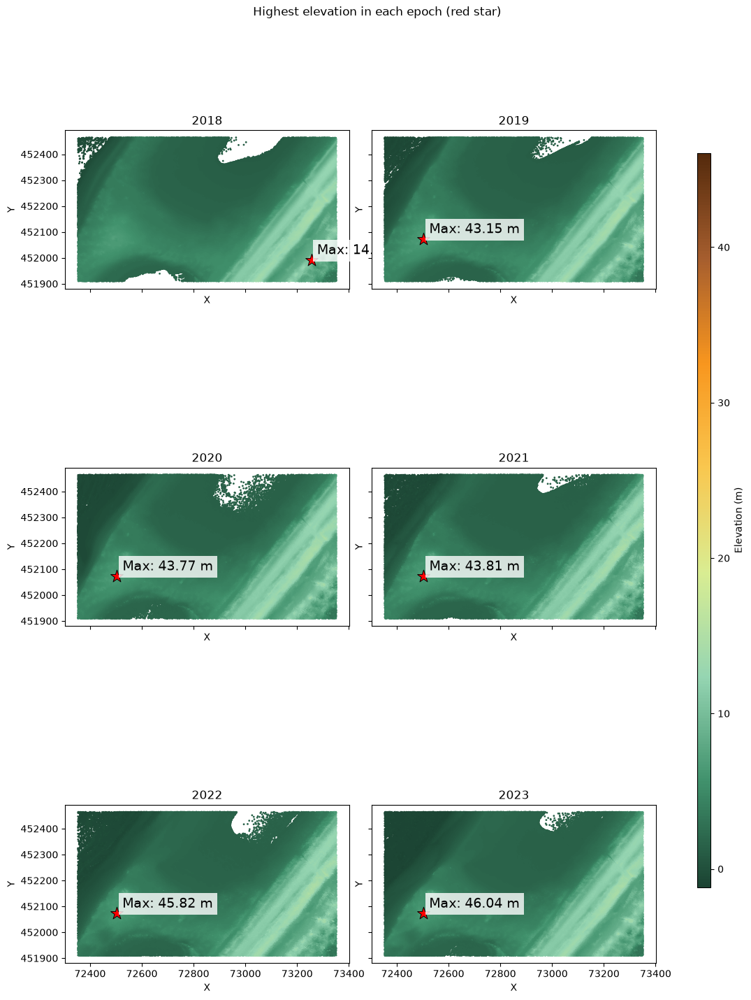

,Epoch,X,Y,Elevation (m)
0,2018,73254.65,451992.09,14.90
1,2019,72502.79,452073.17,43.15
2,2020,72503.08,452073.09,43.77
3,2021,72503.08,452073.06,43.81
4,2022,72502.46,452072.90,45.82
5,2023,72502.48,452072.80,46.04


In [54]:
from matplotlib.colors import LinearSegmentedColormap

# Custom elevation color ramp, with no white
colors = [
    "#1B4332",  # Dark green: lowest elevations
    "#40916C",  # Green
    "#95D5B2",  # Light green
    "#D9ED92",  # Yellow-green
    "#F9C74F",  # Yellow
    "#F8961E",  # Orange
    "#A65E2E",  # Brown
    "#542A0C",  # Dark brown: highest elevations
]

elevation_cmap = LinearSegmentedColormap.from_list(
    "terrain_no_white", colors, N=256
)

ncols = 2
# Prepare a plotting sample and find the exact highest point for each epoch.
# Read in chunks to avoid loading all six point clouds into memory at once.
clouds = []
highest_points = []
global_min_z = np.inf
global_max_z = -np.inf

for path in files:
    sample_chunks = []
    highest = None

    with laspy.open(path) as las:
        step = max(1, int(np.ceil(las.header.point_count / 200_000)))
        point_offset = 0

        for chunk in las.chunk_iterator(500_000):
            xyz = np.column_stack((chunk.x, chunk.y, chunk.z))
            finite = np.isfinite(xyz).all(axis=1)
            xyz = xyz[finite]

            if len(xyz) == 0:
                point_offset += len(chunk)
                continue

            global_min_z = min(global_min_z, float(xyz[:, 2].min()))
            global_max_z = max(global_max_z, float(xyz[:, 2].max()))

            indices = np.arange(point_offset, point_offset + len(chunk))
            keep = finite & (indices % step == 0)
            if keep.any():
                sample_chunks.append(
                    np.column_stack((chunk.x[keep], chunk.y[keep], chunk.z[keep]))
                )

            chunk_highest_idx = int(np.nanargmax(np.where(finite, chunk.z, np.nan)))
            candidate = np.array(
                [chunk.x[chunk_highest_idx], chunk.y[chunk_highest_idx],
                 chunk.z[chunk_highest_idx]],
                dtype=float,
            )
            if highest is None or candidate[2] > highest[2]:
                highest = candidate

            point_offset += len(chunk)

    sample = np.vstack(sample_chunks)
    clouds.append((path, sample, highest))
    highest_points.append({
        "Epoch": path.stem[:4],
        "X": highest[0],
        "Y": highest[1],
        "Elevation (m)": highest[2],
    })

nrows = (len(clouds) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols + 0.9, 5 * nrows),
    sharex=True, sharey=True, squeeze=False
)

for ax, (path, sample, highest) in zip(axes.flat, clouds):
    plot = ax.scatter(
        sample[:, 0], sample[:, 1],
        c=sample[:, 2], s=1,
        cmap=elevation_cmap,
        vmin=global_min_z, vmax=global_max_z,
        rasterized=True
    )

    # Mark the highest point in red
    ax.scatter(
        highest[0], highest[1],
        marker="*", s=180, c="red",
        edgecolors="black", linewidths=0.7, zorder=3
    )

    # Annotate the maximum elevation
    ax.annotate(
        f"Max: {highest[2]:.2f} m",
        (highest[0], highest[1]),
        xytext=(6, 6), textcoords="offset points",
        fontsize=14, color="black",
        bbox={
            "facecolor": "white",
            "alpha": 0.8,
            "edgecolor": "none"
        }
    )

    ax.set_title(path.stem[:4])
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")



# Leave room for the colorbar on the right
fig.tight_layout(rect=[0, 0, 0.90, 0.95])
fig.subplots_adjust(wspace=0.08, hspace=0.12)

# Add a separate colorbar outside the plots
cbar_ax = fig.add_axes([0.92, 0.15, 0.018, 0.70])
fig.colorbar(plot, cax=cbar_ax, label="Elevation (m)")

fig.suptitle(
    "Highest elevation in each epoch (red star)",
    y=0.99
)


plt.show()
display(pd.DataFrame(highest_points).round(2))

When comparing the years there is a significant shift of the color range towards the green, this is due to the significant difference between 2018 and the following years. This may be due to a potential data gap in 2018. 

In [55]:
# How close are the highest points in each epoch to the 2018 reference cloud?
from scipy.spatial import cKDTree
import numpy as np
import pandas as pd
import py4dgeo

# Load the full 2018 cloud (not the subsampled points used for plotting).
reference_path = next(
    (Path(path) for path in files if Path(path).stem.startswith("2018")),
    None
)
if reference_path is None:
    raise FileNotFoundError("Could not find the 2018 LAS/LAZ file in pc_files.")

reference_points = py4dgeo.read_from_las(str(reference_path)).cloud
valid = np.isfinite(reference_points[:, :3]).all(axis=1)
reference_points = reference_points[valid]

tree = cKDTree(reference_points[:, :2])
radius = 3.0  # metres

checks = []
for point in highest_points:
    if str(point["Epoch"]) == "2018":
        continue

    xy = [point["X"], point["Y"]]
    nearest_distance, _ = tree.query(xy)
    nearby_indices = tree.query_ball_point(xy, r=radius)

    checks.append({
        "Epoch": point["Epoch"],
        "Maximum elevation (m)": point["Elevation (m)"],
        "Nearest 2018 point (m)": nearest_distance,
        f"2018 points within {radius:g} m": len(nearby_indices),
        f"Highest 2018 elevation within {radius:g} m": (
            reference_points[nearby_indices, 2].max()
            if nearby_indices else np.nan
        ),
        "Coverage at this radius": (
            "Nearby 2018 points" if nearby_indices
            else "No 2018 points nearby (possible gap)"
        ),
    })

display(pd.DataFrame(checks).round(2))

[2026-10-15 09:11:46][INFO] Reading point cloud from file '/Users/emelia/Documents/Zandmotor_Multispectral/clipped_point_clouds/2018_Zandmotor_30DZ1_clipped.laz'


,Epoch,Maximum elevation (m),Nearest 2018 point (m),2018 points within 3 m,Highest 2018 elevation within 3 m,Coverage at this radius
0,2019,43.15,2.95,3,6.27,Nearby 2018 points
1,2020,43.77,2.75,2,6.27,Nearby 2018 points
2,2021,43.81,2.76,2,6.27,Nearby 2018 points
3,2022,45.82,2.95,2,6.19,Nearby 2018 points
4,2023,46.04,2.90,2,6.19,Nearby 2018 points


To verify if the low elevation maxium of 2018 is simply due to a data gap, the distance and values of the nearby 2018 points and the maxium elevation of each year were compared. Overall, there is roughly a 3m gap in the location where the high elevations are typically measured. However, the highest nearby 2018 elevations are only 6.19–6.27 m, while the later-year maximum elevations are 43.15–46.04 m. This significant difference may suggest that a narrow peak point was missed in 2018 due to a data gap or that there has been a significant sand input between the 2018-2019 measurements. Since the 2019 43m point is consistent and increasing over the years, it is unlikely an error. 

## Question 2: M3C2 parameters and rationale

*For epochs to be added, you now configure the M3C2 algorithm to derive the change values. We would like to set the normals purely vertically, so we define a customized computation of cylinder `directions`. In this flat topography and predominant process of sand deposition and erosion, it can be suitable to orient the normals purely vertically, because most change occurs in this direction.The registration error is set at 5 cm, as this is the specified systematic geometric error in recent AHN flights.*

*Choose the cylinder radius and max distance parameters. Consider: What values for the cylinder radius and max_distance are appropriate for our dataset? How would your estimated distances change under varying radii?*

M3C2 is a defined **direction-based approach**, it stands for **Multi-scale Model to Model Could Comparison**, which is typically used for **complexe topography**. The advantage is that by comparing local surface neighborhoods it can measure changes directly between point clouds without requiring individual points to match exactly nor identical sampling densities. It can also estimate uncertainty based on factors such as local surface roughness, point density and measurement uncertainty. However, it is sensitive to **point cloud misalignment**, if one of the scans has no usable points, it also cannot determine any change. 

I used all points in the 2018 reference cloud as corepoints, and compared each later epoch with that reference. I set the M3C2 direction to **vertical**, using the vector `[0, 0, 1]`, because the assignment focuses on elevation change from sand deposition and erosion.

The selected parameter values are:

- **Cylinder radius: 1 m**: sets the neighborhood width used to gather points for the comparison. A larger radius can produce a more stable, spatially averaged result, but may smooth over smaller features. A smaller radius can retain more local detail, but may be noisier if fewer points fall within the neighborhood. **1m is chosen to capture smaller landforms since the interest is dune change**.
- **Maximum distance: 3 m**: limits how far py4dgeo searches along the comparison direction for points in the other cloud. It should be large enough to capture the expected changes, but not so large that unrelated surfaces are matched. Under natural conditions the zandmotor is expected to have **a maxium elevation change 1-2m over a year, however due to human interventions this may be higher, so a distance of 3m is chosen**.
- **Registration error: 0.05 m**: accounts for an assumed 5 cm error from cloud alignment when estimating uncertainty. It's the **specified systematic geometric error in recent AHN flights**. This is an input uncertainty, not a correction that moves the points.


***Why M3C2 rather than C2C distances or DEM differencing?***

M3C2 compares point clouds using **neighborhoods** around selected corepoints and reports distances in a defined direction, with uncertainty information. This can make it more robust for uneven point spacing and local surface roughness than simple cloud-to-cloud nearest-point distances, which can be strongly affected by sampling density and may not represent change in a consistent direction.

Rasterizing the clouds and subtracting DEMs is another valid approach for elevation change, but it requires choosing a grid size and producing a surface for each epoch. Results can depend on that resolution and on how gaps are interpolated; gridding may also discard some point-level detail. M3C2 works directly with the point clouds and provides uncertainty estimates, which are useful when judging whether measured changes exceed the expected error.

In [56]:
# Configure M3C2 to measure change along the positive vertical axis.
# The calculation is performed in the next cell when epochs are added.
class M3C2_Vertical(py4dgeo.M3C2):
    def directions(self):
        return np.array([0.0, 0.0, 1.0])


# Use all points in the reference epoch as corepoints.
# All points in the reference epoch are used as corepoints by default.
# Do not reassign analysis.corepoints after the analysis exists.
# Reassigning corepoints requires starting a new SpatiotemporalAnalysis.

# Configure the cylinder neighborhood, search distance, and registration error.
analysis.m3c2 = M3C2_Vertical(
    cyl_radius=1.0,
    max_distance=3,
    registration_error=0.05,
)

# The following cell calls analysis.add_epochs(*epochs), which computes and
# stores the upward M3C2 distances for the later epochs relative to the reference.


Now we add all the other epochs with their timestamps:

In [59]:
# Create a list to collect epoch objects
epochs = []
for e, pc_file in enumerate(pc_list[1:], start=1):
    epoch = py4dgeo.read_from_las(pc_file)
    epoch.timestamp = timestamps[e]
    epochs.append(epoch)

# Add epoch objects to the spatiotemporal analysis object to compute M3C2 distances
analysis.corepoints = reference_epoch.cloud
analysis.add_epochs(*epochs)

# Print the spatiotemporal analysis data for 3 corepoints and all epochs, respectively
print(f"Space-time distance array:\n{analysis.distances[:3,:]}")
print(
    f"Uncertainties of M3C2 distance calculation:\n{analysis.uncertainties['lodetection'][:3, :]}"
)

[2026-10-15 09:17:42][INFO] Reading point cloud from file '/Users/emelia/Documents/Zandmotor_Multispectral/clipped_point_clouds/2019_Zandmotor_30DZ1_clipped.laz'
[2026-10-15 09:17:42][INFO] Reading point cloud from file '/Users/emelia/Documents/Zandmotor_Multispectral/clipped_point_clouds/2020_Zandmotor_30DZ1_clipped.laz'
[2026-10-15 09:17:43][INFO] Reading point cloud from file '/Users/emelia/Documents/Zandmotor_Multispectral/clipped_point_clouds/2021_Zandmotor_30DZ1_clipped.laz'
[2026-10-15 09:17:44][INFO] Reading point cloud from file '/Users/emelia/Documents/Zandmotor_Multispectral/clipped_point_clouds/2022_Zandmotor_30DZ1_clipped.laz'
[2026-10-15 09:17:45][INFO] Reading point cloud from file '/Users/emelia/Documents/Zandmotor_Multispectral/clipped_point_clouds/2023_Zandmotor_30DZ1_clipped.laz'
[2026-10-15 09:17:45][INFO] Initializing Epoch object from given point cloud
[2026-10-15 09:17:45][INFO] Building KDTree structure with leaf parameter 10
[2026-10-15 09:17:45][INFO] Saving e

 The inital spatiotemporal analysis data for **3 corepoints** and all epoch shows the uncertainty associated with the M3C2 distance measurements.These **LoD values** of approximately 0.15–0.23 m suggest that changes smaller than roughly **15–23 cm may not be distinguishable from zero** for these example core points, under the current uncertainty model. This does not mean that all smaller changes are physically absent. It means the analysis does not provide sufficient evidence to distinguish them from zero at the specified detection level.
For interpretating the dune erosion and sedimentation, this is important: a red or blue region on the M3C2 map may show a measured difference, but the difference should be compared with the LoD before concluding that significant geomorphological change occurred.

## Question 3: Patterns of change since 2018

In [63]:
# Rows are corepoints; columns are comparison epochs (2019, 2020, ...).
import numpy as np
import pandas as pd


distances = np.asarray(analysis.distances, dtype=float)
lod = np.asarray(analysis.uncertainties["lodetection"], dtype=float)

if distances.ndim != 2:
    raise ValueError(f"Expected a 2D distance array, got shape {distances.shape}.")
if lod.shape != distances.shape:
    raise ValueError(
        f"Distance and LoD arrays must have the same shape; "
        f"got {distances.shape} and {lod.shape}."
    )
if len(files) - 1 != distances.shape[1]:
    raise ValueError(
        f"Expected {len(files) - 1} comparison epochs from files, "
        f"but the M3C2 array has {distances.shape[1]} columns."
    )

summary = []

for column, epoch_file in enumerate(files[1:]):
    d = distances[:, column]
    threshold = lod[:, column]

    valid_distance = np.isfinite(d)
    valid_pair = valid_distance & np.isfinite(threshold)
    detected = valid_pair & (np.abs(d) > threshold)

    valid_values = d[valid_distance]
    paired_count = int(valid_pair.sum())

    summary.append({
        "Epoch": epoch_file.name[:4],
        "Corepoints": len(d),
        "Valid distances": int(valid_distance.sum()),
        "No-data distances": int((~valid_distance).sum()),
        "No-data (%)": 100 * (~valid_distance).mean(),
        "Mean distance (m)": np.mean(valid_values) if len(valid_values) else np.nan,
        "Median distance (m)": np.median(valid_values) if len(valid_values) else np.nan,
        "Distance std (m)": np.std(valid_values) if len(valid_values) else np.nan,
        "Minimum (m)": np.min(valid_values) if len(valid_values) else np.nan,
        "Maximum (m)": np.max(valid_values) if len(valid_values) else np.nan,
        "Median LoD (m)": np.median(threshold[valid_pair]) if paired_count else np.nan,
        "Distances > LoD": int(detected.sum()),
        "Distances > LoD (%)": (
            100 * detected.sum() / paired_count if paired_count else np.nan
        ),
    })

m3c2_summary = pd.DataFrame(summary).round(3)
display(m3c2_summary)

,Epoch,Corepoints,Valid distances,No-data distances,No-data (%),Mean distance (m),Median distance (m),Distance std (m),Minimum (m),Maximum (m),Median LoD (m),Distances > LoD,Distances > LoD (%)
0,2019,1334663,1325245,9418,0.706,-0.127,-0.028,0.490,-3.081,1.827,0.121,298312,22.610
1,2020,1334663,1309153,25510,1.911,-0.144,-0.008,0.648,-3.313,2.491,0.119,520231,39.978
2,2021,1334663,1312223,22440,1.681,-0.147,-0.013,0.718,-3.108,2.939,0.117,688572,52.524
3,2022,1334663,1253374,81289,6.091,-0.094,0.049,0.783,-3.068,3.075,0.118,806462,64.498
4,2023,1334663,1243720,90943,6.814,-0.165,0.019,0.812,-3.061,3.068,0.118,765929,61.661


Relative to 2018, **median vertical changes at the corepoints were small**, ranging from −0.028 to +0.049 m. These values are **smaller** in magnitude than the **median LoD of approximately 0.12 m**, indicating that the typical measured change was small compared with the typical detection threshold. However, the proportion of valid corepoints with change exceeding their local LoD increased from 22.6% in 2019 to 64.5% in 2022, then was 61.7% in 2023. This indicates that a larger proportion of the evaluable reference corepoints have distances exceeding their local detection thresholds which means that **more locations experienced detectable surface changes over time**. The **mean distances were more negative than medians in all epochs**, suggesting that **larger negative changes** influenced the averages, possibly indicating signs of longterm erosion or flattening/deepening of larger areas of the dune relative to the dune growth; in **2022–2023**, positive medians alongside negative means indicate **mixed spatial patterns**. However,the proportion of corepoints with **no valid M3C2 distance increased** from 0.7% in 2019 to 6.1–6.8% in 2022–2023. This means that a larger number of locations could not be included in the later comparisons, potentially **affecting the comparability** of results between years. The impact depends on the spatial distribution of these missing values, as concentrated gaps could cause changes in specific areas to be underrepresented. Since this is a coastal areas, it is assumed to be related to the tidal and water level differences. 

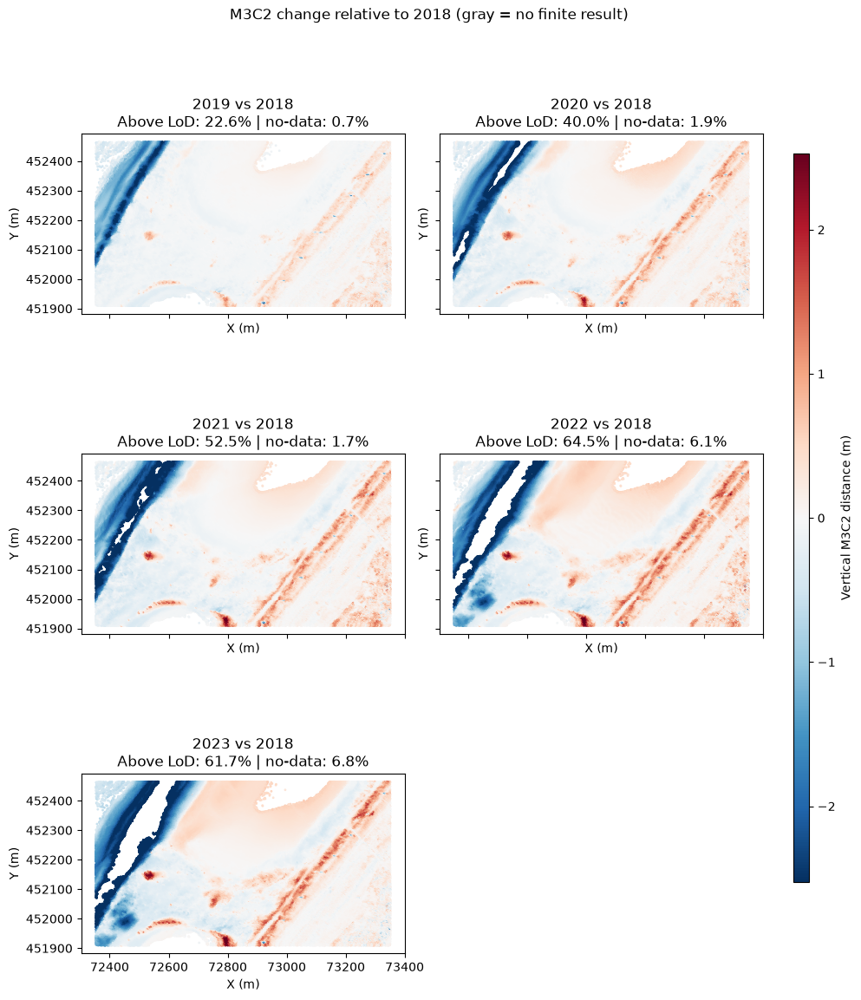

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

D = np.asarray(analysis.distances, dtype=float)  # [corepoint, epoch]
LOD = np.asarray(analysis.uncertainties["lodetection"], dtype=float)
corepoints = np.asarray(analysis.corepoints.cloud)

if D.ndim != 2 or LOD.shape != D.shape:
    raise ValueError(f"Unexpected array shapes: distances={D.shape}, LoD={LOD.shape}")
if len(corepoints) != D.shape[0]:
    raise ValueError("Corepoint count does not match the distance array.")
if len(files) - 1 != D.shape[1]:
    raise ValueError("Expected one comparison epoch for each file after 2018.")

# Draw the same random subset in every panel to keep plotting responsive.
rng = np.random.default_rng(42)
max_points = 250_000
if len(corepoints) > max_points:
    plot_indices = np.sort(rng.choice(len(corepoints), max_points, replace=False))
else:
    plot_indices = np.arange(len(corepoints))

finite_values = D[np.isfinite(D)]
if finite_values.size == 0:
    raise ValueError("There are no finite M3C2 distances to plot.")

# Use one symmetric scale for all epochs; the 98th percentile limits
# the visual influence of extreme values.
color_limit = np.nanpercentile(np.abs(finite_values), 98)
if not np.isfinite(color_limit) or color_limit <= 0:
    color_limit = np.nanmax(np.abs(finite_values))
if color_limit <= 0:
    color_limit = 1.0

norm = TwoSlopeNorm(vmin=-color_limit, vcenter=0, vmax=color_limit)
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("lightgray")

ncols = 2
nrows = (D.shape[1] + ncols - 1) // ncols
fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(5 * ncols, 4 * nrows),
    sharex=True, sharey=True, squeeze=False
)

for epoch_idx, ax in enumerate(axes.flat[:D.shape[1]]):
    values = D[plot_indices, epoch_idx]
    valid_all = np.isfinite(D[:, epoch_idx])
    paired_all = valid_all & np.isfinite(LOD[:, epoch_idx])
    detected_all = paired_all & (np.abs(D[:, epoch_idx]) > LOD[:, epoch_idx])

    no_data_pct = 100 * (~valid_all).mean()
    detected_pct = (
        100 * detected_all.sum() / paired_all.sum()
        if paired_all.any() else np.nan
    )

    plot = ax.scatter(
        corepoints[plot_indices, 0],
        corepoints[plot_indices, 1],
        c=np.ma.masked_invalid(values),
        cmap=cmap,
        norm=norm,
        s=1,
        rasterized=True,
    )
    ax.set_title(
        f"{files[epoch_idx + 1].name[:4]} vs 2018\n"
        f"Above LoD: {detected_pct:.1f}% | no-data: {no_data_pct:.1f}%"
    )
    ax.set_aspect("equal")
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")

for ax in axes.flat[D.shape[1]:]:
    ax.set_visible(False)

# Reserve space on the right and place the colorbar in its own axis.
fig.tight_layout(rect=[0, 0, 0.90, 0.95])
cbar_ax = fig.add_axes([0.92, 0.15, 0.018, 0.70])
fig.colorbar(plot, cax=cbar_ax, label="Vertical M3C2 distance (m)")
fig.suptitle("M3C2 change relative to 2018 (gray = no finite result)", y=0.99)
plt.show()

With the upward comparison direction, **positive distances indicate upward change**, whereas negative distances indicate downward change. White areas represent no-data regions. The color scale is limited to the 98th percentile, meaning that a small number of extreme values may be visually clipped.

The results show consistent spatial patterns of dune and vegetation growth at the Zandmotor, similar to assignment 1. The increasing contrast over time highlights **areas of sediment accumulation** (darker red) **surrounded by areas of potential erosion** (light blue). This pattern may reflect the influence of local topography on sediment transport: higher dunes and established vegetation can channel or concentrate wind and wave/tidal action through adjacent lower-lying areas, potentially intensifying erosion in these locations.

## Question 4: Change in elevation of corepoints over time 

Different core points were selected to be representative of different types of change in the study area. 2 are located in the heightening dunes south of the area,  3  are positioned landwards towards the more stable and dry dunes, and the remaining are positioned in the lowering surfaces around the center (previously observed).

In [ ]:
# plot some examples of the M3C2 distances for a specific core point and epoch

cp_idx_sel = 30000  # selected core point index
epoch_idx_sel = 1  # selected epoch index

# Create the figure
fig = plt.figure(figsize=(15, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax2 = fig.add_subplot(1, 2, 2)

# Get the corepoints
corepoints = analysis.corepoints.cloud

# get change values of last epoch for all corepoints
distances = analysis.distances
distances_epoch = [d[epoch_idx_sel] for d in distances]

# Get the time series of changes at a specific core point locations
coord_sel = analysis.corepoints.cloud[cp_idx_sel]
timeseries_sel = distances[cp_idx_sel]

# Get the list of timestamps from the reference epoch timestamp and timedeltas
timestamps = [t + analysis.reference_epoch.timestamp for t in analysis.timedeltas]

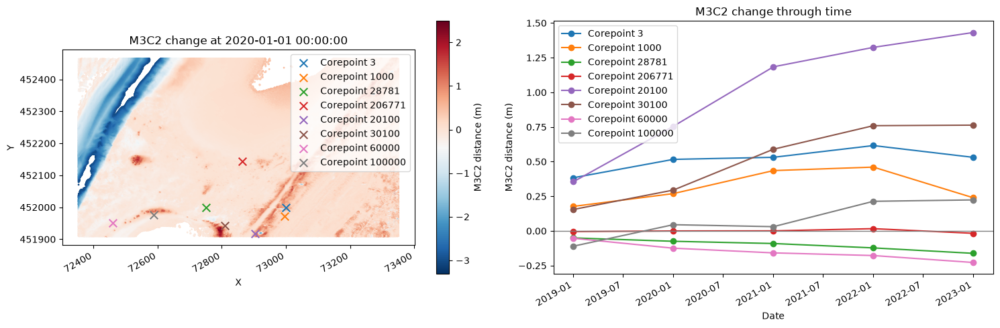

In [82]:
# your code
import numpy as np

cp_indices_sel = [3, 1000, 28781, 206771, 20100, 30100, 60000, 100000]
epoch_idx_sel = 1

corepoints = analysis.corepoints.cloud
distances = np.asarray(analysis.distances)
timestamps = [
    t + analysis.reference_epoch.timestamp
    for t in analysis.timedeltas
]
distances_epoch = distances[:, epoch_idx_sel]

assert distances.shape[0] == len(corepoints)
assert distances.shape[1] == len(timestamps)
assert all(0 <= idx < len(corepoints) for idx in cp_indices_sel)
assert 0 <= epoch_idx_sel < distances.shape[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Map of change at the selected epoch
plot = ax1.scatter(
    corepoints[:, 0], corepoints[:, 1],
    c=distances_epoch, s=1, cmap="RdBu_r"
)
for n, cp_idx in enumerate(cp_indices_sel, start=1):
    coord = corepoints[cp_idx]
    ax1.scatter(
        coord[0], coord[1],
        marker="x", s=70, color=f"C{n - 1}",
        label=f"Corepoint {cp_idx}"
    )

ax1.set_title(f"M3C2 change at {timestamps[epoch_idx_sel]}")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_aspect("equal")
ax1.legend()
fig.colorbar(plot, ax=ax1, label="M3C2 distance (m)")

# Time series for all three selected corepoints
for n, cp_idx in enumerate(cp_indices_sel, start=1):
    ax2.plot(
        timestamps, distances[cp_idx, :],
        marker="o", color=f"C{n - 1}",
        label=f"Corepoint {cp_idx}"
    )

ax2.axhline(0, color="gray", linewidth=1)
ax2.set_title("M3C2 change through time")
ax2.set_xlabel("Date")
ax2.set_ylabel("M3C2 distance (m)")
ax2.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

The map shows the spatial distribution of positive and negative M3C2 distances for a selected epoch, while the time-series plot illustrates how surface change at the selected corepoints evolves relative to 2018. The red corepoint shows relatively stable surface elevation, whereas the green and pink corepoints show a slight decreasing trend, reaching approximately −0.25 m. In contrast, the remaining corepoints generally show increasing elevation relative to 2018, with the **strongest increases occurring in higher-elevation areas further inland and to the south of the study area**.
However, the **yellow corepoint begins to show a decreasing trend after 2022**, unlike the nearby blue corepoint. This may **reflect local variations in wind-driven sediment transport**, whereby sand accumulates on the higher foredune, potentially reducing the amount of sediment transported to areas further inland. 

Furthermore, the presence of **increasing and decreasing trends in close proximity in the southern part** of the study area suggests that accumulation and erosion may occur in neighbouring locations, highlighting the spatial variability of dune dynamics. For instance, this may reflect the **influence of dune morphology on local wind flow**. As sand accumulates (and/or vegetation forms), changes in dune height and shape can **redirect airflow and create local variations in wind speed and turbulence, potentially increasing erosion** in some areas while promoting deposition in others. This may contribute to the spatially variable patterns of surface change observed in the southern part of the study area, although further evidence is needed to confirm this mechanism.

## Times series without NaNs (missing values)

In [83]:
import numpy as np

# In this notebook, distances are indexed [corepoint, epoch]. 
# D is a NumPy array made from analysis.distances; the code expects its rows to be corepoints and its columns to be epochs.
D = np.asarray(analysis.distances)
corepoints = analysis.corepoints.cloud

print("Distances shape (corepoints, epochs):", D.shape)
print("NaN count per epoch:", np.isnan(D).sum(axis=0))

# Keep locations that have a valid distance at every epoch.
valid = np.isfinite(D).all(axis=1)
D_clean = D[valid, :]
corepoints_clean = corepoints[valid]

print(f"Kept {valid.sum()} of {len(valid)} corepoints")
print(np.isfinite(D_clean).all())  # should be True

Distances shape (corepoints, epochs): (1334663, 5)
NaN count per epoch: [ 9418 25510 22440 81289 90943]
Kept 1225084 of 1334663 corepoints
True


Total corepoints: 1,334,663
Retained: 1,225,084 (91.79%)
Excluded: 109,579 (8.21%)


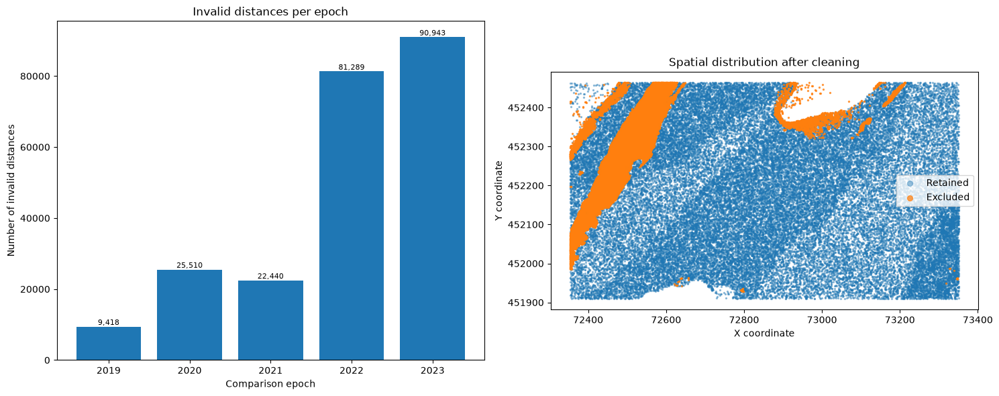

In [86]:

import numpy as np
import matplotlib.pyplot as plt

# Identify corepoints with at least one invalid distance
excluded = ~valid

n_total = len(valid)
n_kept = int(valid.sum())
n_excluded = int(excluded.sum())

print(f"Total corepoints: {n_total:,}")
print(f"Retained: {n_kept:,} ({100*n_kept/n_total:.2f}%)")
print(f"Excluded: {n_excluded:,} ({100*n_excluded/n_total:.2f}%)")

# Number of invalid distances in each epoch
invalid_per_epoch = (~np.isfinite(D)).sum(axis=0)
valid_per_epoch = np.isfinite(D).sum(axis=0)

epoch_labels = ["2019", "2020", "2021", "2022", "2023"]
if len(epoch_labels) != D.shape[1]:
    epoch_labels = [f"Epoch {i+1}" for i in range(D.shape[1])]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# 1. Show invalid distances in each epoch
ax1.bar(epoch_labels, invalid_per_epoch)
ax1.set_title("Invalid distances per epoch")
ax1.set_xlabel("Comparison epoch")
ax1.set_ylabel("Number of invalid distances")
ax1.ticklabel_format(axis="y", style="plain")

for i, count in enumerate(invalid_per_epoch):
    ax1.text(i, count, f"{count:,}", ha="center", va="bottom", fontsize=8)

# 2. Show where corepoints were retained or excluded
# Randomly sample points for faster plotting
rng = np.random.default_rng(42)
max_points = 100_000

def sample_indices(mask, limit):
    indices = np.flatnonzero(mask)
    if len(indices) > limit:
        indices = rng.choice(indices, size=limit, replace=False)
    return indices

kept_idx = sample_indices(valid, max_points // 2)
excluded_idx = sample_indices(excluded, max_points // 2)

ax2.scatter(
    corepoints[kept_idx, 0],
    corepoints[kept_idx, 1],
    s=2, alpha=0.4, label="Retained"
)
ax2.scatter(
    corepoints[excluded_idx, 0],
    corepoints[excluded_idx, 1],
    s=2, alpha=0.7, label="Excluded"
)

ax2.set_title("Spatial distribution after cleaning")
ax2.set_xlabel("X coordinate")
ax2.set_ylabel("Y coordinate")
ax2.set_aspect("equal")
ax2.legend(markerscale=4)

plt.tight_layout()
plt.show()


Approximately **92% of the corepoints were retained** after removing locations with invalid distances in at least one epoch. The **excluded points were concentrated mainly in or near the intertidal zone and waterbodies**. The number of invalid distances was highest in 2022 and 2023, with approximately 81,000 and 91,000 invalid distances, respectively. This may reflect differences in survey coverage or point-cloud characteristics between years. 


## Clustering of similar change patterns
*In the following you are going to use K-Means clustering to identify regions of similar elevation change throughout your point cloud time series, following Kuschnerus et al. (2021).*

*Cluster your data using the distances per epoch (`analysis.distances`) as features using KMeans clustering. Test varying values for K.*

## Question 5 & 6: Kmean cluster labels per corepoint & Clusters best capturing the variability of changes occuring

K-means groups points by similarity in their distance time series, not by geographical proximity. Thus, two points far apart can belong to the same cluster if their measured changes follow similar patterns. 

K=2: inertia=8.07e+05
K=3: inertia=5.72e+05
K=4: inertia=4.12e+05
K=5: inertia=3.15e+05
K=6: inertia=2.53e+05
K=7: inertia=2.1e+05
K=8: inertia=1.79e+05
K=20: inertia=7.77e+04


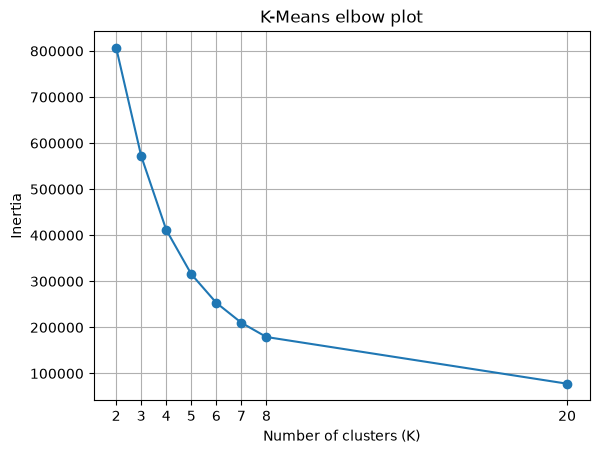

In [128]:
# your code

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

#  the cleaned distance array and corepoint coordinates are used for clustering
X = D_clean  # rows = locations; columns = epochs
coords = corepoints_clean[:, :2]

assert np.isfinite(X).all()
assert len(X) == len(coords)

#testing different numbers of clusters (K) to find the best fit using the "elbow method"
# Inertia measures the sum of squared distances between each time series and the centre of its assigned cluster. 
# Importantly: lower inertia means the data points fit more closely around their cluster centres.
#As you increase K, inertia will generally decrease because the algorithm has more clusters available to represent the data
k_values = [2, 3, 4, 5, 6, 7, 8, 20]
models = {}
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X)
    models[k] = labels
    inertias.append(model.inertia_)
    print(f"K={k}: inertia={model.inertia_:.3g}")

# Inertia normally decreases as K increases; I look for where the decrease
# starts to level off ("elbow").
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means elbow plot")
plt.xticks(k_values)
plt.grid(True)
plt.show()

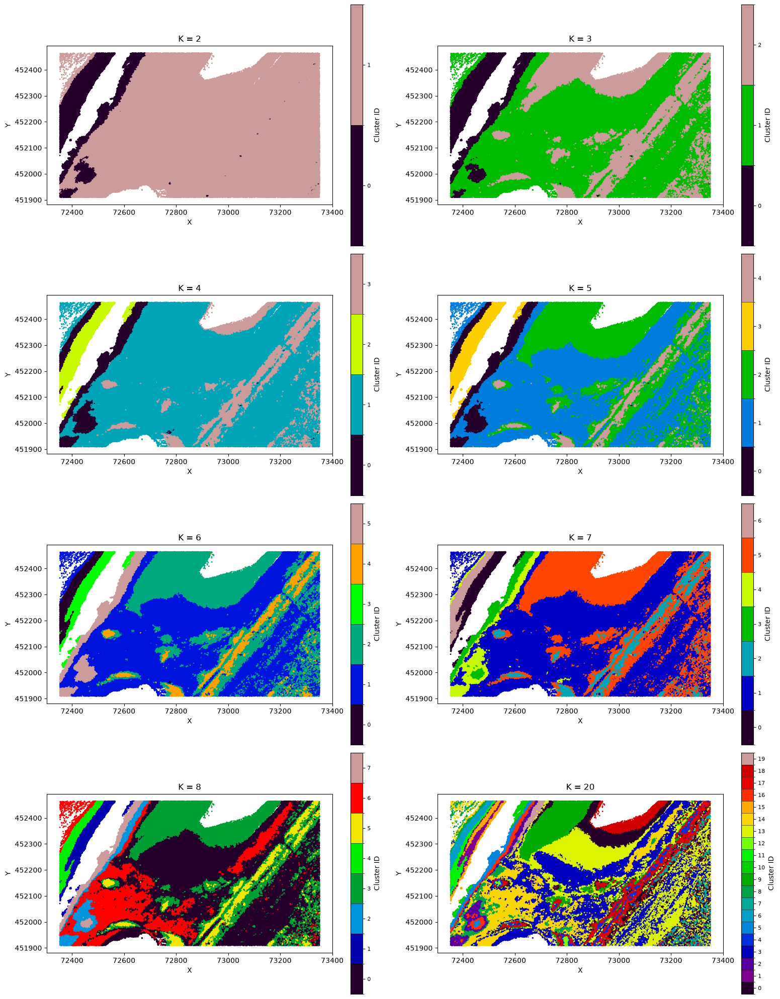

In [133]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# For faster, clearer maps, display a random subset of locations
rng = np.random.default_rng(42)
plot_idx = rng.choice(
    len(coords),
    size=min(250_000, len(coords)),
    replace=False
)

# Automatically create one subplot for each K value
ncols = 2
nrows = int(np.ceil(len(k_values) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 5 * nrows),
    squeeze=False
)
axes = axes.ravel()

for i, k in enumerate(k_values):
    ax = axes[i]

    # Create a discrete palette with no white or near-white colours
    candidate_colors = plt.get_cmap("nipy_spectral")(
        np.linspace(0, 1, 1000)
    )
    rgb = candidate_colors[:, :3]
    brightness = (
        0.2126 * rgb[:, 0]
        + 0.7152 * rgb[:, 1]
        + 0.0722 * rgb[:, 2]
    )
    saturation = rgb.max(axis=1) - rgb.min(axis=1)

    candidate_colors = candidate_colors[
        (brightness < 0.90) & (saturation > 0.15)
    ]

    # Select exactly one colour for each cluster
    indices = np.linspace(
        0, len(candidate_colors) - 1, k
    ).astype(int)

    cmap = mcolors.ListedColormap(candidate_colors[indices])

    # Assign each integer cluster ID to a separate colour interval
    boundaries = np.arange(-0.5, k + 0.5, 1)
    norm = mcolors.BoundaryNorm(boundaries, cmap.N)

    scatter = ax.scatter(
        coords[plot_idx, 0],
        coords[plot_idx, 1],
        c=models[k][plot_idx],
        s=1,
        cmap=cmap,
        norm=norm,
        rasterized=True
    )

    ax.set_title(f"K = {k}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal")

    # Show discrete cluster IDs on the colourbar
    cbar = fig.colorbar(
        scatter,
        ax=ax,
        boundaries=boundaries,
        ticks=np.arange(k),
        spacing="uniform",
        drawedges=True
    )
    cbar.set_label("Cluster ID")
    cbar.ax.tick_params(labelsize=8)

# Hide any unused panels
for i in range(len(k_values), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


This **elbow test** helps identify when the cluster number stops substantially reducing inertia. The most significant decrease in inertia is observed when K arrives at 3 or 4. **General geomorphological processes appear relatively well represented at K=3 and are coherent with the features from the satellite images observed in Assignment 1**. Beyond K=5, there is only significant change at much higher K values. 
Visually, however, **the more subtle patterns/contrasts similar to those in the inital M3C2 relative changes observed in question 3 only seem apparent around K=8**. While this doesn't establish that K = 8 is the best clustering solution, it is worth checking whether the clusters have distinct mean time series and interpretable spatial distributions. With the K=20, the algorithm can distinguish more detailed patterns in the temporal evolution of surface change. However, this does not necessarily mean that there are 20 distinct geomorphological processes or meaningful surface-change categories.

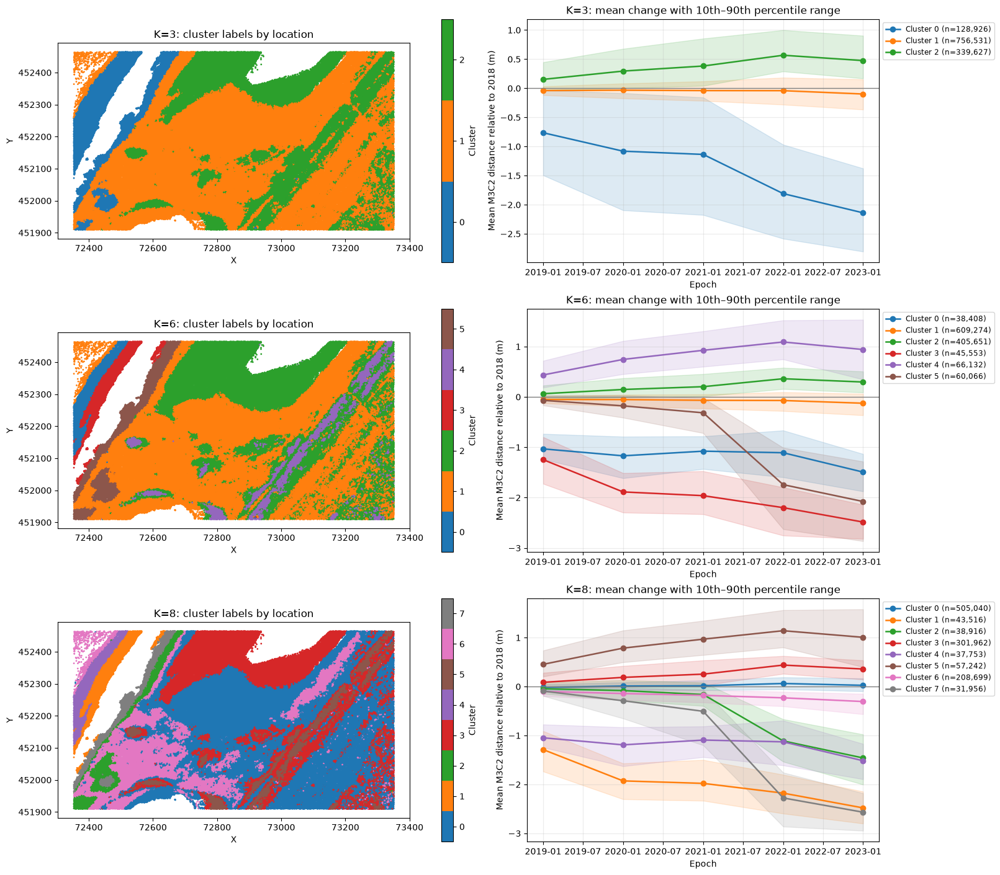

In [140]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Reuse the KMeans labels from the clustering cell above.
k_values_compare = (3, 6, 8)
coords = np.asarray(corepoints_clean)[:, :2]
X = np.asarray(D_clean, dtype=float)  # rows = corepoints, columns = epochs

assert X.shape[0] == len(coords) and X.shape[1] == len(timestamps)
assert all(k in models for k in k_values_compare)

rng = np.random.default_rng(42)
plot_idx = rng.choice(len(coords), size=min(250_000, len(coords)), replace=False)

cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(3, 2, figsize=(16, 14), constrained_layout=True)

for row, k in enumerate(k_values_compare):
    labels = np.asarray(models[k])
    assert labels.shape == (len(X),)

    map_ax, series_ax = axes[row]
    cluster_colors = [cmap(cluster_id % 10) for cluster_id in range(k)]

    # --- Spatial cluster map ---
    map_plot = map_ax.scatter(
        coords[plot_idx, 0],
        coords[plot_idx, 1],
        c=labels[plot_idx],
        s=1,
        cmap=ListedColormap(cluster_colors),
        vmin=-0.5,
        vmax=k - 0.5,
        rasterized=True
    )

    map_ax.set(
        title=f"K={k}: cluster labels by location",
        xlabel="X",
        ylabel="Y",
        aspect="equal"
    )
    fig.colorbar(map_plot, ax=map_ax, ticks=np.arange(k), label="Cluster")

    # --- Mean time series with 10th–90th percentile ranges ---
    for cluster_id in range(k):
        members = labels == cluster_id

        if not members.any():
            continue

        cluster_data = X[members, :]

        # Calculate statistics separately for each epoch.
        mean = np.nanmean(cluster_data, axis=0)
        p10 = np.nanpercentile(cluster_data, 10, axis=0)
        p90 = np.nanpercentile(cluster_data, 90, axis=0)

        color = cluster_colors[cluster_id]

        # Shaded percentile range, behind the mean line.
        series_ax.fill_between(
            timestamps,
            p10,
            p90,
            color=color,
            alpha=0.15
        )

        # Mean line.
        series_ax.plot(
            timestamps,
            mean,
            color=color,
            marker="o",
            linewidth=1.8,
            label=f"Cluster {cluster_id} (n={members.sum():,})"
        )

    series_ax.axhline(0, color="gray", linewidth=1)

    series_ax.set(
        title=f"K={k}: mean change with 10th–90th percentile range",
        xlabel="Epoch",
        ylabel="Mean M3C2 distance relative to 2018 (m)"
    )

    series_ax.legend(
        loc="upper left",
        bbox_to_anchor=(1, 1),
        fontsize="small"
    )
    series_ax.grid(alpha=0.25)

plt.show()

### Comparing and interpreting K=3, K=6 and K=8

K=3 gives broad groups of similar change. When observing it's percentile ranges, cluster 1 and 2 show less variability than cluster 0. Since cluster 0 is located around the intertidal zone, this higher variability can be explained by the naturally more dynamic sediment transport. The cluster 2 is situated more landwards and around the waterbodies, the increasing trend could thus reflect patches of sediment accretion and vegetation growth. On the other hand, cluster 1 remains relatively stable over the entire area, with a slight decrease in 2023.  

In comparison, K=6 and K=8 split those cluster groups into more specific temporal profiles (for example, different change magnitudes, timing, or reversals). Interestingly, here K=6's cluster 5 (brown) shows a more sudden decrease between 2021 and 2022 infront of the intertidal zone, this was not previously distinguishable. Similarly, K=8 distinguishes even more subtle changes. Specifically, K=8's clusters 0 and 5 (pink and blue) help distinguish where the slight decreasing trend observed in K3's cluster 1 (yellow) is actually taking place. However, these spatially scattered groups or profiles with small differences relative to M3C2 level of detection may also simply reflect noise, coverage, or measurement uncertainty. 


### Additional ways to optimise K values
In addition to the elbow test, additional data driven ways to select the most appropriate cluster number can include running a silhouette analysis and to check the differences in local level of detection (LoD): 

A **silhouette analysis** evaluates how well each data point fits within its assigned cluster compared with neighbouring clusters, providing a measure of cluster cohesion and separation. It is appropriate here because it offers a quantitative basis for comparing different numbers of clusters and assessing whether the M3C2 distance trajectories form distinct groups, thereby supporting the selection of a suitable \(K\) value. For each corepoint, the silhouette score compares two things:
- Within-cluster distance (a): how different that corepoint's M3C2 distance trajectory is from other corepoints in the same cluster.
- Nearest-other-cluster distance (b): how different that trajectory is from the most similar alternative cluster.

The silhouette score is calculated as:
$$
s = \frac{b-a}{\max(a,b)}
$$

A high **positive score** (max 1) means that the corepoint is much **more similar to its own cluster than to neighbouring clusters**. A score **near zero** means that corepoint **lies near a boundary between clusters**, or its assignment is not clearly distinguished. A **negative score** (minimum -1) means the corepoint may be **closer to another cluster than the one it was assigned to**.

,K,Inertia,Silhouette
0,2,807163.9773,0.7525
1,3,571863.7264,0.4710
2,4,411600.6489,0.5550
3,5,315490.4776,0.4397
4,6,253198.7495,0.4457
5,7,209941.0052,0.4605
6,8,179044.8063,0.4175
7,9,155258.7345,0.4149
8,10,143644.6117,0.4096
9,11,132364.8045,0.4102


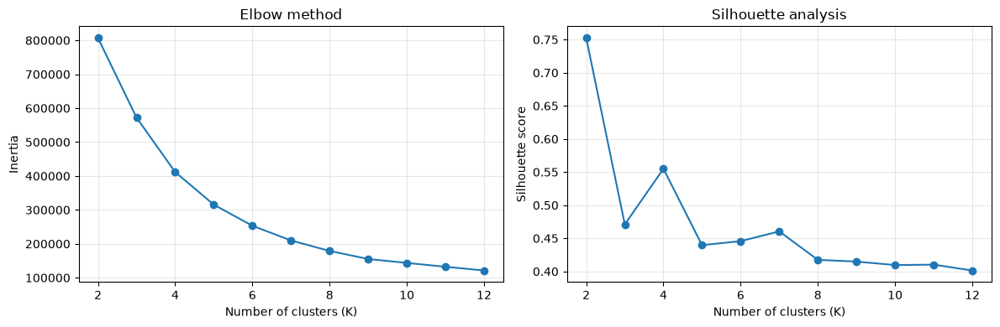

In [148]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = np.asarray(D_clean, dtype=float)

# Sample rows for efficient silhouette estimation.
rng = np.random.default_rng(42)
sample_size = min(10_000, len(X))
sample_idx = rng.choice(len(X), size=sample_size, replace=False)
X_sample = X[sample_idx]

k_values = range(2, 13)
results = []

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = km.fit_predict(X)

    sample_labels = labels[sample_idx]
    score = silhouette_score(X_sample, sample_labels)

    results.append({
        "K": k,
        "Inertia": km.inertia_,
        "Silhouette": score
    })

scores_df = __import__("pandas").DataFrame(results)
display(scores_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(scores_df["K"], scores_df["Inertia"], marker="o")
axes[0].set(
    xlabel="Number of clusters (K)",
    ylabel="Inertia",
    title="Elbow method"
)
axes[0].grid(alpha=0.3)

axes[1].plot(scores_df["K"], scores_df["Silhouette"], marker="o")
axes[1].set(
    xlabel="Number of clusters (K)",
    ylabel="Silhouette score",
    title="Silhouette analysis"
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Similar to the previous Elbow analysis, the decrease in inertia values starts to level out after K=8. However, it does not provide a clearcut optimal k value.

Additionally, the silhouette analysis helps quantify how well-separated your clusters are. The decrease in silhouette score from \(K=2\) to \(K=3\) is substantial. It then **rises at \(K=4\)**, before generally declining as more clusters are added  suggesting that cluster beyond 4 would be generally less distinct. While K2 score the highest, \(K=4\) may offer a useful compromise if it reveals more meaningful and detectable surface-change patterns. 

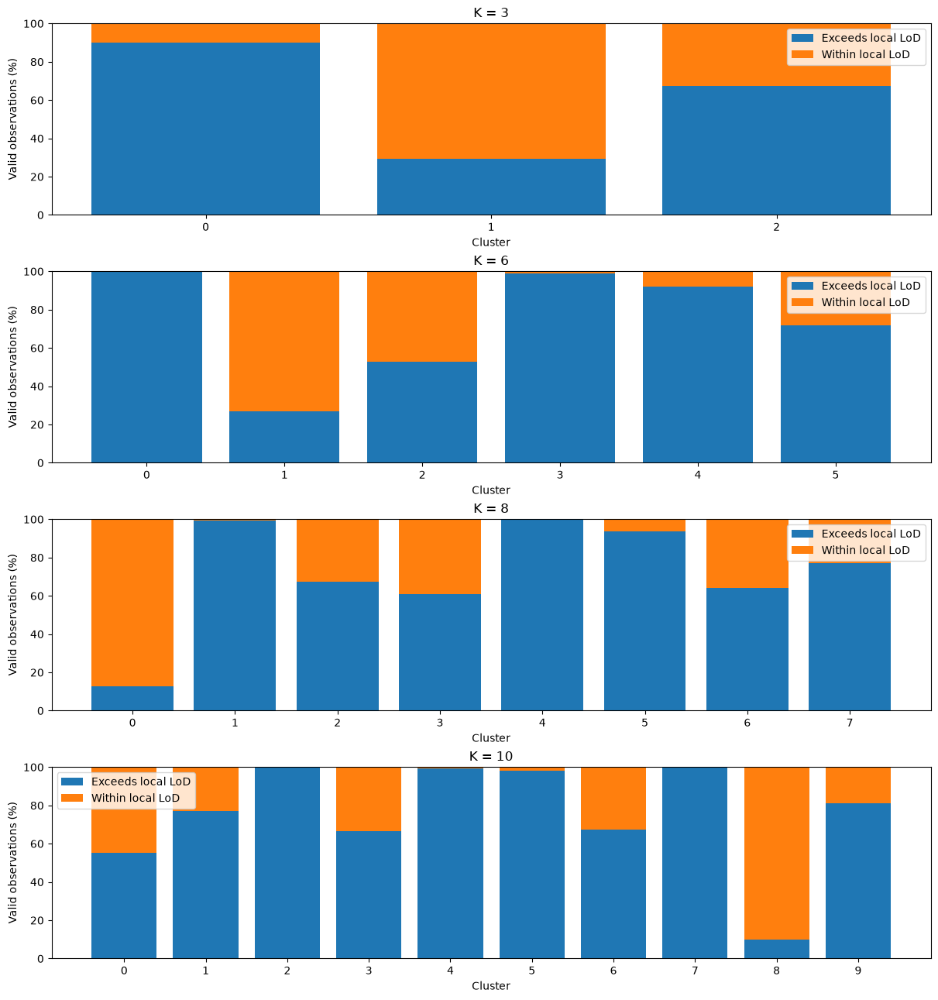

In [150]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X = np.asarray(D_clean, dtype=float)
L = np.asarray(LoD_clean, dtype=float)

k_values = [3, 6, 8, 10]
summary = []

for k in k_values:
    if k not in models:
        models[k] = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        ).fit_predict(X)

    labels = np.asarray(models[k])

    for cluster_id in range(k):
        mask = labels == cluster_id
        d = X[mask].ravel()
        lod = L[mask].ravel()

        valid = np.isfinite(d) & np.isfinite(lod)
        d, lod = d[valid], lod[valid]

        if len(d) == 0:
            continue

        positive = d > lod
        negative = d < -lod
        detectable = positive | negative

        summary.append({
            "K": k,
            "Cluster": cluster_id,
            "Detectable (%)": 100 * detectable.mean(),
            "Within LoD (%)": 100 * (~detectable).mean(),
            "Positive (%)": 100 * positive.mean(),
            "Negative (%)": 100 * negative.mean(),
        })

summary_df = pd.DataFrame(summary)

fig, axes = plt.subplots(
    len(k_values), 1,
    figsize=(12, 3.2 * len(k_values)),
    constrained_layout=True
)

for ax, k in zip(axes, k_values):
    sub = summary_df[summary_df["K"] == k]
    x = np.arange(len(sub))

    ax.bar(x, sub["Detectable (%)"], label="Exceeds local LoD")
    ax.bar(
        x, sub["Within LoD (%)"],
        bottom=sub["Detectable (%)"],
        label="Within local LoD"
    )

    ax.set_title(f"K = {k}")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Valid observations (%)")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["Cluster"].astype(str))
    ax.set_ylim(0, 100)
    ax.legend()

plt.show()

Furthermore, for most clusters in the \(K\)-cluster solution, a substantial proportion of M3C2 distances exceeded the local level of detection (LoD). This indicates that the identified temporal patterns are largely associated with detectable surface changes rather than differences that fall entirely within the measurement uncertainty. However, the LoD assessment alone does not establish the optimal number of clusters, which must also be evaluated based on cluster separation, spatial coherence, and interpretability.

Although most K clusters contained predominantly detectable surface changes, they all contained at least one cluster with a larger proportion of M3C2 distances within the local LoD (i.e. the predominantly orange plots). This suggests that the changes associated with this "orange" cluster are generally small relative to the detection threshold and cannot be confidently distinguished from zero at the selected confidence level. The cluster may nevertheless represent a distinct temporal pattern, potentially associated with relative surface stability or subtle changes below the detection threshold.

While these tools may inform the cluster choice, they all have limitations. For example, the elbow method relies on the visual identification of a point where the reduction in inertia begins to diminish, which can be subjective, particularly when no distinct elbow is present. Silhouette analysis quantifies how well observations fit within their assigned clusters compared with neighbouring clusters, but it does not account for the geomorphological significance of the identified patterns, their spatial coherence, or whether the observed changes exceed the local level of detection (LoD). Furthermore, the silhouette score may favour a smaller number of well-separated clusters, potentially overlooking meaningful subgroups within broader clusters. The results also depend on the selected features, distance metric, and data preprocessing.
Consequently, neither method independently determines the most appropriate number of clusters. The final choice should also consider the spatial distribution, temporal M3C2-distance profiles, and detectability of changes within each cluster. 
If the four-cluster solution distinguishes meaningful and spatially coherent change patterns that are combined in the two-cluster solution, \(K = 4\) may provide a more informative representation of surface-change variability despite its lower silhouette score. However, this additional detail should be weighed against the risk of creating clusters that are less clearly separated or difficult to interpret geomorphologically.

### Concluding answer

**While a data-driven methods are helpful, the choice of \(K\) ultimately depends on the research objectives** and the desired level of detail. If the aim is to identify **broad patterns** of erosion and accumulation, a smaller number of clusters, such as \(K=3 or 4\), may be sufficient for estimations. However, if the objective is to **distinguish differences in the magnitude and temporal development of surface changes**, a larger number of clusters, such as \(K=6\), may provide a more detailed representation. An even higher value, such as \(K=8\), may reveal **subtle patterns in areas that otherwise appear relatively stable**. For example, cluster 6 represents areas with a gradual decrease in elevation relative to the 2018 reference, whereas nearby areas assigned to cluster 0 remain comparatively stable. This illustrates how increasing \(K\) can reveal spatially distinct patterns that may be masked when fewer clusters are used. 

Additionally, the **temporal resolution** of the dataset is another important consideration when selecting the number of clusters. Annual observations are more suitable for identifying broad, long-term patterns of surface change, whereas monthly observations may capture shorter-term processes and fluctuations that are not visible at an annual scale. Consequently, a **larger number of clusters may be useful for distinguishing more complex temporal trajectories when regular observations are available**. However, increasing the temporal resolution does not necessarily justify increasing the number of clusters, as short-term variations may be smaller than the local level of detection (LoD) or reflect measurement uncertainty. The selected number of clusters should therefore reflect both the temporal scale of the research question and the ability to distinguish meaningful change patterns from uncertainty in the measurements.

However, increasing the number of clusters also **increases the complexity of the classification and may result in the fragmentation of similar change patterns** into smaller groups. Therefore, the choice of \(K\) should consider not only the spatial and temporal interpretability of the clusters, but also their **statistical separation, size, and spatial coherence. As shown, quantitative measures, such as inertia and silhouette scores**, can support this decision, although no single metric necessarily identifies the most meaningful solution. The observed differences should be evaluated against the **local level of detection (LoD)** to assess whether they exceed measurement uncertainty. The preferred number of clusters should therefore provide a balance between capturing meaningful variability in surface change, producing interpretable spatial patterns, and avoiding unnecessary complexity.

## Question 7: Comparision with manually identified patterns of change (Q3) & vegetation 

Since we are **interested in vegetation and localised sand accumulation**, **a higher and potentially more detailed K=8 is chosen** regardless of the silhouette results because a lower inertia clustering is prioritised. 

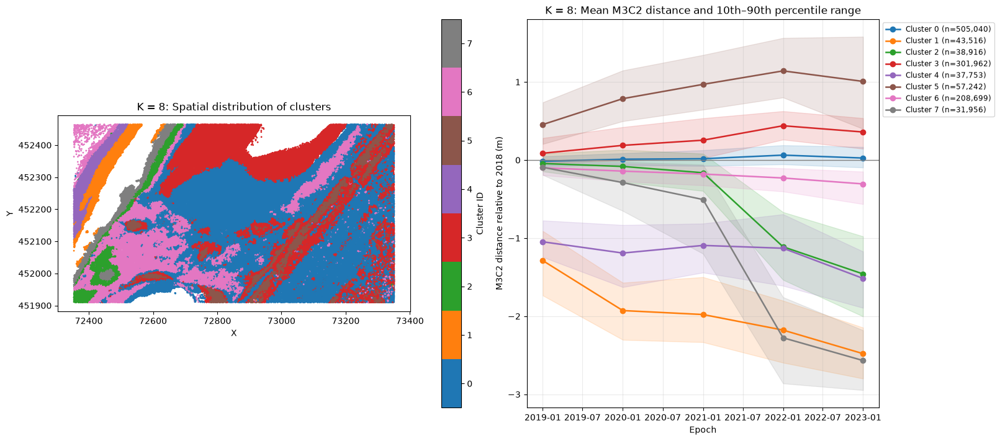

In [153]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Data and KMeans labels
k = 8
coords = np.asarray(corepoints_clean)[:, :2]
X = np.asarray(D_clean, dtype=float)
labels = np.asarray(models[k])

assert X.shape[0] == len(coords)
assert X.shape[1] == len(timestamps)
assert labels.shape == (len(X),)

# Random sample for spatial plotting
rng = np.random.default_rng(42)
plot_idx = rng.choice(
    len(coords),
    size=min(250_000, len(coords)),
    replace=False
)

# Distinct colours for the 8 clusters
cmap = plt.get_cmap("tab10")
cluster_colors = [cmap(i) for i in range(k)]
cluster_cmap = ListedColormap(cluster_colors)

# Create figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    constrained_layout=True
)

map_ax, series_ax = axes

# --- Spatial cluster map ---
map_plot = map_ax.scatter(
    coords[plot_idx, 0],
    coords[plot_idx, 1],
    c=labels[plot_idx],
    s=1,
    cmap=cluster_cmap,
    vmin=-0.5,
    vmax=k - 0.5,
    rasterized=True
)

map_ax.set(
    title="K = 8: Spatial distribution of clusters",
    xlabel="X",
    ylabel="Y",
    aspect="equal"
)

fig.colorbar(
    map_plot,
    ax=map_ax,
    ticks=np.arange(k),
    label="Cluster ID"
)

# --- Mean time series with 10th–90th percentile ranges ---
for cluster_id in range(k):
    members = labels == cluster_id

    if not members.any():
        continue

    cluster_data = X[members, :]

    mean = np.nanmean(cluster_data, axis=0)
    p10 = np.nanpercentile(cluster_data, 10, axis=0)
    p90 = np.nanpercentile(cluster_data, 90, axis=0)

    color = cluster_colors[cluster_id]

    # Shaded percentile range
    series_ax.fill_between(
        timestamps,
        p10,
        p90,
        color=color,
        alpha=0.15
    )

    # Mean distance
    series_ax.plot(
        timestamps,
        mean,
        color=color,
        marker="o",
        linewidth=1.8,
        label=f"Cluster {cluster_id} (n={members.sum():,})"
    )

series_ax.axhline(0, color="gray", linewidth=1)

series_ax.set(
    title="K = 8: Mean M3C2 distance and 10th–90th percentile range",
    xlabel="Epoch",
    ylabel="M3C2 distance relative to 2018 (m)"
)

series_ax.legend(
    loc="upper left",
    bbox_to_anchor=(1, 1),
    fontsize="small"
)

series_ax.grid(alpha=0.25)

plt.show()

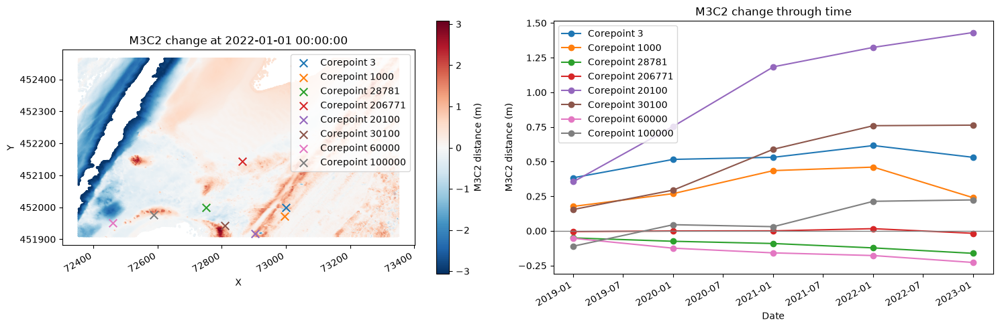

In [158]:
# your code
import numpy as np

cp_indices_sel = [3, 1000, 28781, 206771, 20100, 30100, 60000, 100000]
epoch_idx_sel = 3

corepoints = analysis.corepoints.cloud
distances = np.asarray(analysis.distances)
timestamps = [
    t + analysis.reference_epoch.timestamp
    for t in analysis.timedeltas
]
distances_epoch = distances[:, epoch_idx_sel]

assert distances.shape[0] == len(corepoints)
assert distances.shape[1] == len(timestamps)
assert all(0 <= idx < len(corepoints) for idx in cp_indices_sel)
assert 0 <= epoch_idx_sel < distances.shape[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Map of change at the selected epoch
plot = ax1.scatter(
    corepoints[:, 0], corepoints[:, 1],
    c=distances_epoch, s=1, cmap="RdBu_r"
)
for n, cp_idx in enumerate(cp_indices_sel, start=1):
    coord = corepoints[cp_idx]
    ax1.scatter(
        coord[0], coord[1],
        marker="x", s=70, color=f"C{n - 1}",
        label=f"Corepoint {cp_idx}"
    )

ax1.set_title(f"M3C2 change at {timestamps[epoch_idx_sel]}")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_aspect("equal")
ax1.legend()
fig.colorbar(plot, ax=ax1, label="M3C2 distance (m)")

# Time series for all three selected corepoints
for n, cp_idx in enumerate(cp_indices_sel, start=1):
    ax2.plot(
        timestamps, distances[cp_idx, :],
        marker="o", color=f"C{n - 1}",
        label=f"Corepoint {cp_idx}"
    )

ax2.axhline(0, color="gray", linewidth=1)
ax2.set_title("M3C2 change through time")
ax2.set_xlabel("Date")
ax2.set_ylabel("M3C2 distance (m)")
ax2.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

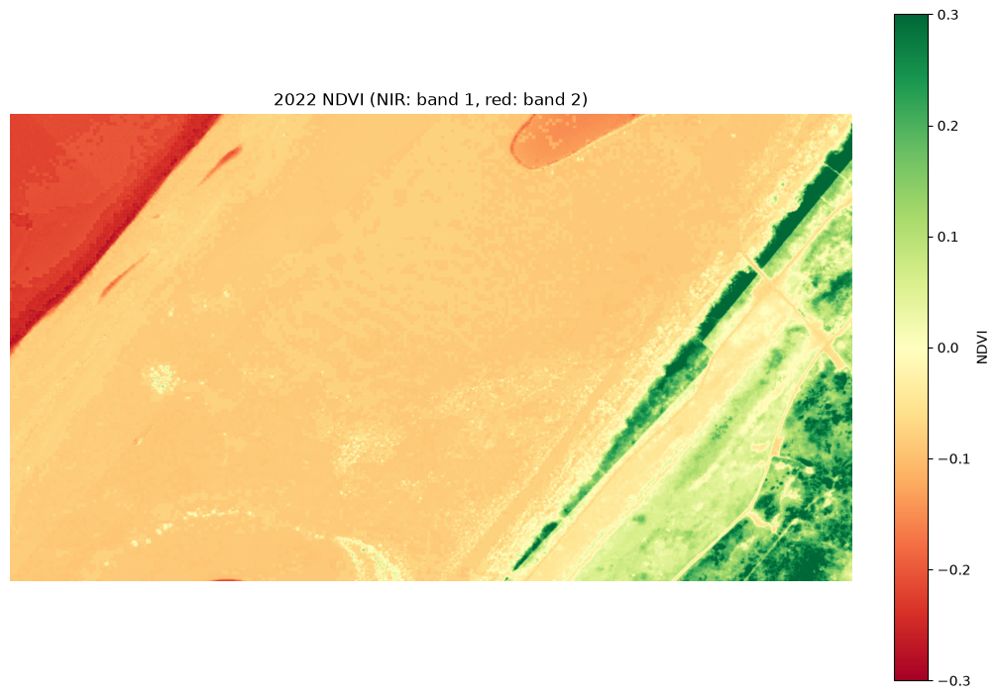

In [159]:
from pathlib import Path
import numpy as np
import rasterio as rio
import matplotlib.pyplot as plt

cropped_dir = Path("cropped_to_reference_grid")
year = 2022

image_path = cropped_dir / f"{year}_CIR_30DZ1.tiff"

with rio.open(image_path) as src:
    cir_bands = src.read((1, 2), masked=True).astype(np.float32)
    nir, red = cir_bands.filled(np.nan)

# Calculate NDVI
denominator = nir + red
valid = (
    np.isfinite(nir)
    & np.isfinite(red)
    & (denominator != 0)
)

ndvi = np.full(nir.shape, np.nan, dtype=np.float32)
np.divide(nir - red, denominator, out=ndvi, where=valid)

# Plot NDVI for 2022
cmap = plt.get_cmap("RdYlGn").copy()
cmap.set_bad("lightgray")

fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)

image = ax.imshow(ndvi, cmap=cmap, vmin=-0.3, vmax=0.3)
ax.set_title("2022 NDVI (NIR: band 1, red: band 2)")
ax.axis("off")

fig.colorbar(image, ax=ax, label="NDVI", shrink=0.85)

plt.show()

# Store the result for later analysis
ndvi_by_year = {2022: ndvi}

Overall, the manually identified patterns can user to directly avoid less reliable areas, such as tidal zones. However, these areas are automatically included in the K-means clustering, particularly within the orange, grey, and purple clusters. Clustering provides a clear visual representation of spatially similar trends across the study area, whereas the manual method allows for a more targeted and detailed comparison of specific locations.

The spatial patterns of change identified using M3C2 distances also appear to correspond reasonably well with the clustered regions. Both methods help identify potential vegetation patches, particularly in the brown areas. However, as these methods represent elevation changes rather than vegetation directly, they provide less information about vegetation density than an NDVI map. For example, although the southern areas show increased elevation and fall within the same cluster or exhibit similar magnitudes of change, they appear less vegetated in the NDVI map than the more landward areas. This highlights a limitation of using elevation change alone to identify vegetation, as similar elevation changes do not necessarily indicate comparable vegetation density.

## Principal Component Analysis of change patterns
*In the following, you will use principal component analysis (PCA; also referred to as empirical orthogonal functions) as a tool to summarize the change patterns within a spatiotemporal dataset. The method is based on [this master thesis](http://resolver.tudelft.nl/uuid:ce98c4e3-6ca1-4966-a5cf-2120f2fa44bf).*
 
*For this technique, the 4D data shall be represented as a two-dimensional array in which the rows correspond to different epochs, and the columns correspond to each individual [x, y] coordinate where a z or surface change value is represented.*

*Reshape the data from the `SpatiotemporalAnalysis` object so that all coordinates are represented in one axis, i.e. an array holding [time, space]:*


Find coordinates without nan values, and create a new array without nan values:


In [189]:
# your code

distances = np.asarray(analysis.distances, dtype=float)
coords = np.asarray(analysis.corepoints.cloud)[:, :2]

X = distances.transpose()  # [time/epoch, location/corepoint]

# Keep only locations with finite values at every time and valid coordinates.
valid = np.isfinite(X).all(axis=0) & np.isfinite(coords).all(axis=1)
X = X[:, valid]
coords_clean = coords[valid]

# Center each location's time series around its temporal mean.
X = X - np.nanmean(X, axis=0)

print("PCA array [time, space]:", X.shape)
print("Matching coordinates [space, x/y]:", coords_clean.shape)

PCA array [time, space]: (5, 1225084)
Matching coordinates [space, x/y]: (1225084, 2)


PC1 captures the largest amount of variation in the data.
PC2 captures the largest amount of the remaining variation, independently of PC1.
PC3 captures the next largest amount, and so on. Each component is like a different mode of change in the landscape. For example, one component might distinguish locations that generally gain elevation from those that lose elevation, while another might highlight areas that change differently between particular epochs

This output shows that the data and coordinates are now aligned correctly: the array contains 5 time epochs and 1,225,084 spatial locations, with a matching pair of x/y coordinates for each location. After removing locations with missing or invalid values and centring the data across time, the dataset is ready for PCA, provided any remaining preprocessing requirements are met

## Questions 8 & 9: Visualise PCA loadings (spatial) and scores (temporal) of first 3 components & K cluster comparison

Compute the loading and scores of the prinicpal components in 'NaN-free' X:

In [190]:
# your code
import numpy as np
from sklearn.decomposition import PCA

if X.ndim != 2 or not np.isfinite(X).all():
    raise ValueError("X must be a 2D array containing only finite values.")
if min(X.shape) < 2:
    raise ValueError(f"PCA needs at least two epochs and two locations; got {X.shape}.")

pca = PCA()  # retain all components
scores = pca.fit_transform(X)   # [time, component]
loadings = pca.components_.T    # [location, component]
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

print("Scores [time, component]:", scores.shape)
print("Loadings [location, component]:", loadings.shape)
print("Explained variance ratio:", explained_variance_ratio)
print("Cumulative explained variance:", cumulative_variance)

Scores [time, component]: (5, 5)
Loadings [location, component]: (1225084, 5)
Explained variance ratio: [8.48547742e-01 8.47731581e-02 4.69883355e-02 1.96907645e-02
 1.16804063e-29]
Cumulative explained variance: [0.84854774 0.9333209  0.98030924 1.         1.        ]


Variance explained: PC1: 84.85%, PC2: 8.48%, PC3: 4.70%
First three PCs together explain 98.03% of variance.


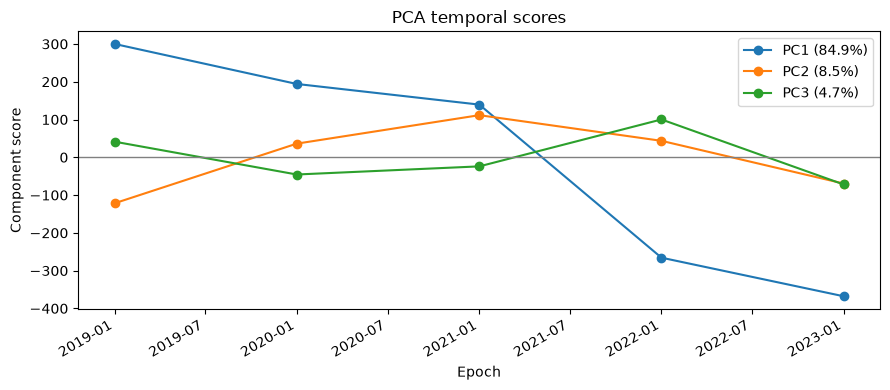

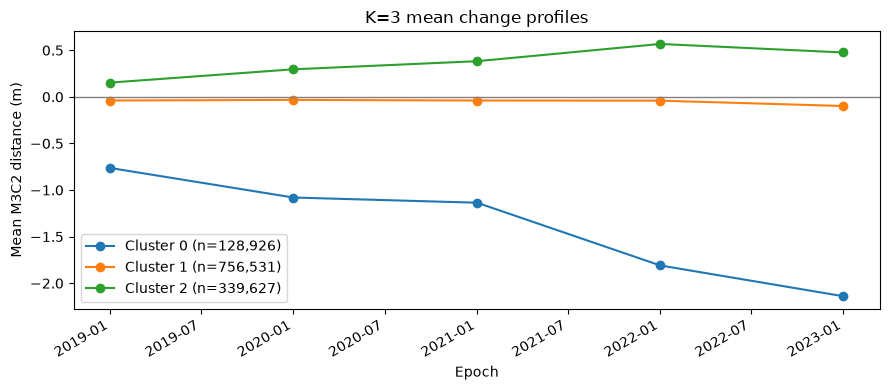

In [191]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA

# Use the same complete locations and ordering as KMeans.
X_change = np.asarray(D_clean, dtype=float).T  # [epoch, location]
X_pca = X_change.copy()
coords_pca = np.asarray(corepoints_clean)[:, :2]
if not np.isfinite(X_pca).all():
    raise ValueError("PCA input must contain only finite distances.")
if X_pca.shape[1] != len(coords_pca) or X_pca.shape[1] != len(models[3]):
    raise ValueError("PCA locations, coordinates, and KMeans labels are not aligned.")
if X_pca.shape[0] < 3:
    raise ValueError("At least three epochs are required to plot the first three PCs.")

# Center each location over time, then calculate the first three PCs.
X_pca -= X_pca.mean(axis=0, keepdims=True)
pca = PCA(n_components=3)
scores = pca.fit_transform(X_pca)       # [epoch, component]
loadings = pca.components_.T            # [location, component]
variance = pca.explained_variance_ratio_
print("Variance explained: " + ", ".join(
    f"PC{i + 1}: {value:.2%}" for i, value in enumerate(variance)
))
print(f"First three PCs together explain {variance.sum():.2%} of variance.")

pca_dates = [analysis.reference_epoch.timestamp + delta for delta in analysis.timedeltas]
if len(pca_dates) != X_pca.shape[0]:
    raise ValueError("Timestamp count does not match the PCA epoch count.")

# Sample locations for display only; PCA and cluster means use all valid locations.
rng = np.random.default_rng(42)
plot_idx = rng.choice(len(coords_pca), size=min(200_000, len(coords_pca)), replace=False)
cluster_labels = np.asarray(models[3])
cluster_colors = [plt.get_cmap("tab10")(i) for i in range(3)]

fig, ax = plt.subplots(figsize=(9, 4))
for component in range(3):
    ax.plot(
        pca_dates, scores[:, component], marker="o",
        label=f"PC{component + 1} ({variance[component]:.1%})"
    )
ax.axhline(0, color="gray", linewidth=1)
ax.set(title="PCA temporal scores", xlabel="Epoch", ylabel="Component score")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


# Cluster-average change profiles provide a temporal comparison with the PCA scores.
fig, ax = plt.subplots(figsize=(9, 4))
for cluster_id, color in enumerate(cluster_colors):
    members = cluster_labels == cluster_id
    ax.plot(
        pca_dates, X_change[:, members].mean(axis=1), marker="o", color=color,
        label=f"Cluster {cluster_id} (n={members.sum():,})"
    )
ax.axhline(0, color="gray", linewidth=1)
ax.set(title="K=3 mean change profiles", xlabel="Epoch", ylabel="Mean M3C2 distance (m)")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

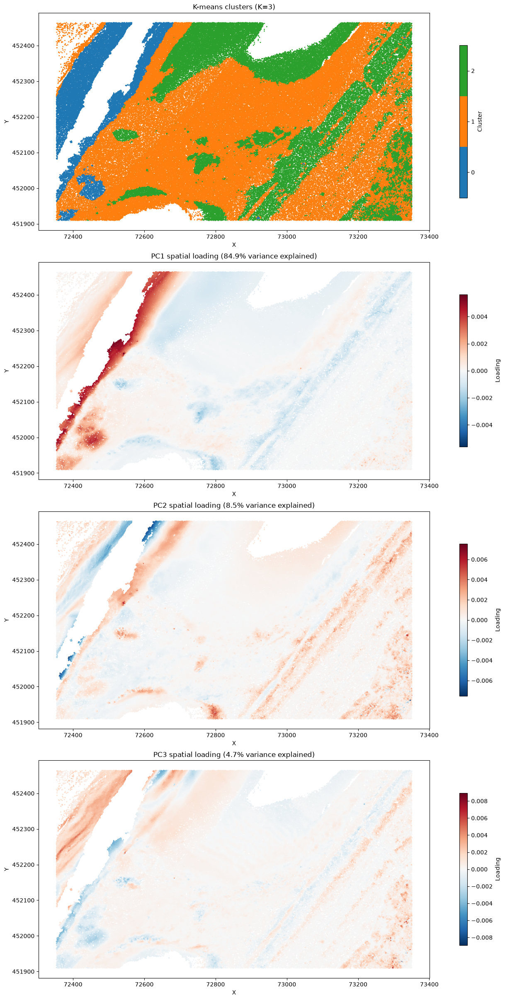

In [192]:

fig, axes = plt.subplots(
    4, 1, figsize=(12, 24), constrained_layout=True
)

# K-means clusters
cluster_plot = axes[0].scatter(
    coords_pca[plot_idx, 0],
    coords_pca[plot_idx, 1],
    c=cluster_labels[plot_idx],
    s=1,
    cmap=ListedColormap(cluster_colors),
    vmin=-0.5,
    vmax=2.5,
    rasterized=True
)
axes[0].set(
    title="K-means clusters (K=3)",
    xlabel="X",
    ylabel="Y",
    aspect="equal"
)
fig.colorbar(cluster_plot, ax=axes[0], ticks=np.arange(3),
             label="Cluster", shrink=0.7)

# Spatial loading maps for PC1, PC2 and PC3
for component, ax in enumerate(axes[1:]):
    values = loadings[:, component]
    limit = np.max(np.abs(values[plot_idx]))
    if limit == 0:
        limit = 1

    plot = ax.scatter(
        coords_pca[plot_idx, 0],
        coords_pca[plot_idx, 1],
        c=values[plot_idx],
        s=1,
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        rasterized=True
    )
    ax.set(
        title=f"PC{component + 1} spatial loading "
              f"({variance[component]:.1%} variance explained)",
        xlabel="X",
        ylabel="Y",
        aspect="equal"
    )
    fig.colorbar(plot, ax=ax, label="Loading", shrink=0.7)

plt.show()


### Conceptual differences between PCA and KMeans

PCA and KMeans summarize change in different ways:

- **PCA loadings** describe the spatial pattern of each principal component: locations with larger absolute loading values contribute more strongly to that pattern. Positive and negative values indicate opposite contributions, but the sign of a component is arbitrary.
- **PCA scores** describe how strongly each component is expressed at each epoch. Together, a component’s score curve and loading map describe a dominant mode of temporal and spatial variation.
- **KMeans labels** assign each location to a discrete group based on similarity across its full change time series. A **KMeans centroid** is the average time series for the locations in that cluster.

So, PCA represents variation as a few continuous, orthogonal patterns, while KMeans partitions locations into groups with similar histories. Their maps may show similar broad zones, but they need not have the same boundaries: PCA components are not clusters, and a KMeans cluster can combine locations that load differently on several components.

Locations with large positive or negative loadings are strongly associated with the component's spatial pattern. Opposite signs indicate opposing relationships with that pattern. Mapping the loadings lets you see where each principal component is most strongly expressed. This is why spatial loadings can be useful for comparing PCA with K-means clusters.

### PCA versus KMeans clusters

KMeans (K=3) divides locations into three groups based on their full change histories. The blue cluster is concentrated along the western side and has increasingly negative mean change, reaching about −2.1 m in 2023. The green cluster occupies much of the northern dune arc and parts of the eastern strip; its mean change is positive, peaking around +0.6 m in 2022. The orange cluster covers most of the central area and stays close to zero, with a small negative mean by 2023. PCA represents spatial patterns as continuous loadings. **PC1 explains 84.9% of the variance** and is strongest along the western strip, broadly corresponding to the area isolated as the **blue KMeans cluster**. **PC2 (8.5%) and PC3 (4.7%)** show finer spatial variation, including narrower bands and localized patches that KMeans combines into its broader groups. The first three PCs explain about 98.0% together.

This is a broad correspondence, not an exact match: KMeans assigns each location to one cluster, while PCA loadings show how strongly a location contributes to a component. Also, loading color alone does not mean erosion or deposition, the component’s sign is arbitrary.

### Combining the methods

One option is to use each location’s first three PCA loadings as its features, then run KMeans on those loading vectors, thus grouping locations according to their combinations of the dominant modes of surface change. This is an interesting approach because it connects the temporal patterns identified by PCA with their spatial distribution, potentially revealing geographically coherent zones with distinct surface-change behaviours. Mapping the resulting clusters and comparing each group’s average original change time series with the PCA score curves can help assess how the spatial groups relate to the dominant temporal patterns. This provides an additional basis for interpreting the clusters geomorphologically, although statistical similarity does not necessarily correspond directly to distinct geomorphological processes.

## Question 10: Insightfulness 

For this dataset, **KMeans is the most insightful single method for summarising the spatial patterns of elevation change**, while manual M3C2 interpretation is essential for assessing their geomorphological significance and uncertainties. PCA also provides a useful complementary summary or even a potential starting point for the M3C2.

The analysis includes over **1.2 million valid locations but only five change epochs**. Manually interpreting every location would be impractical. KMeans addresses this challenge by grouping locations with similar change histories into a small number of classes that can be mapped and compared over time. For example, the K = 3 results show cluster-average profiles characterised by strongly negative change, change close to zero, and positive change. Mapping these clusters makes the broad spatial differences in elevation-change behaviour easier to identify and interpret. PCA is also informative, with the first three components explaining approximately **98% of the variance** in the analysed data. However, its loadings and scores represent mathematical patterns of variation rather than direct classifications of erosion and deposition. Interpreting these patterns requires considering the spatial loading maps and temporal score curves together, and the arbitrary sign of each component must also be taken into account.

Overall, **KMeans is the clearest method for communicating where groups of locations with similar change histories occur and how their average temporal patterns differ**. Manual interpretation of the original M3C2 results can then help assess these patterns against local levels of detection and survey coverage, while PCA can confirm or reveal broader modes of temporal variation. Nevertheless, cluster-average profiles alone do not establish specific geomorphological processes. Changes should be interpreted cautiously, particularly where observed differences fall within the measurement uncertainty.

## References 
* Anders, K., D. Kempf, W. Albert, et al. “Py4dgeo: Open-Source Scientific Software for Topographic Change Analysis in 3D/4D Geographic Point Clouds.” SoftwareX 34 (June 2026): 102670. https://doi.org/10.1016/j.softx.2026.102670.
* Kuschnerus, M., Lindenbergh, R., & Vos, S. (2021). Coastal change patterns from time series clustering of permanent laser scan data. Earth Surface Dynamics, 9 (1), pp. 89-103. doi: [10.5194/esurf-9-89-2021](https://doi.org/10.5194/esurf-9-89-2021).